# Notebook 3 — Ablation Study

Consolidates every ablation this project has run, plus two new ones,
all on UNIFESP:

**Section A -- already measured in earlier notebooks (embedded here as
reported numbers, not re-run):**
1. Light vs. heavy data augmentation (per-backbone, Step 2)
2. Plain BCE vs. hierarchical anatomical-group loss (5-fold CV)
3. No-TTA vs. TTA, single model vs. ensemble, 0.5 vs. tuned threshold (5-fold CV)

**Section B -- new: does the learned fusion gate matter?**
`models_hybrid.py`'s `HybridCNNTransformer` combines its CNN and
Transformer branches with a *learned per-sample gate*. Is that actually
earning its keep over the simplest possible fusion -- a fixed 50/50
average? Trains both variants on the same cv_fold, evaluates both on
the same held-out test set.

**Section C -- new: how much does patient-level leakage actually
inflate validation scores?**
Every other notebook in this project splits by patient_id specifically
to avoid leakage (a patient's images all land in the same fold). This
section deliberately builds the leaky alternative -- the same images,
the same held-out test, just split per-IMAGE instead of per-patient --
trains the same backbone on it, and compares both models' own-reported
validation score against their score on the real held-out test. The
gap is the point: it's what you'd never see without a genuinely
untouched test set.


## 1. Detect the attached UNIFESP images dataset


In [1]:
import os

images_root = None
for cur, dirs, files in os.walk("/kaggle/input"):
    if "train" in dirs and "test" in dirs:
        images_root = cur
        dirs[:] = [d for d in dirs if d not in ("train", "test")]
        break

assert images_root is not None, (
    "Could not find a dataset with train/ and test/ folders under /kaggle/input. "
    "Attach felipekitamura/unifesp-xray-bodypart-classification (Notebook Settings -> Data)."
)
print("Images dataset:", images_root)
IMAGES_DATASET = images_root


Images dataset: /kaggle/input/datasets/felipekitamura/unifesp-xray-bodypart-classification


## 2. Write the pipeline code (embedded, no external dataset needed)


In [2]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/__init__.py", "w", encoding="utf-8") as f:
    f.write('')
print("wrote src/__init__.py")


wrote src/__init__.py


In [3]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/config.py", "w", encoding="utf-8") as f:
    f.write('"""\nCentral config. Two roots, because on Kaggle they\'ll usually be two\ndifferent attached datasets:\n  - DATA_ROOT: where train/, test/ (the DICOM images) live\n  - INDEX_ROOT: where index.csv and splits/folds.csv live\n\nLocally both default to the repo root. On Kaggle, set them explicitly as\nenvironment variables in the notebook\'s first cell, e.g.:\n    import os\n    os.environ["UNIFESP_DATA_ROOT"] = "/kaggle/input/unifesp-xray-bodypart-classification"\n    os.environ["UNIFESP_INDEX_ROOT"] = "/kaggle/input/unifesp-index-files"  # your uploaded index.csv+splits/\n    os.environ["UNIFESP_OUTPUT_DIR"] = "/kaggle/working"\n(see KAGGLE_SETUP.md for the full first-cell snippet.)\n"""\nimport os\n\n_THIS_DIR = os.path.dirname(os.path.abspath(__file__))\n_REPO_ROOT = os.path.dirname(_THIS_DIR)\n\nON_KAGGLE = os.path.exists("/kaggle/input")\n\nif ON_KAGGLE:\n    DATA_ROOT = os.environ.get("UNIFESP_DATA_ROOT", "/kaggle/input")\n    INDEX_ROOT = os.environ.get("UNIFESP_INDEX_ROOT", DATA_ROOT)\n    OUTPUT_DIR = os.environ.get("UNIFESP_OUTPUT_DIR", "/kaggle/working")\nelse:\n    DATA_ROOT = os.environ.get("UNIFESP_DATA_ROOT", _REPO_ROOT)\n    INDEX_ROOT = os.environ.get("UNIFESP_INDEX_ROOT", DATA_ROOT)\n    OUTPUT_DIR = os.environ.get("UNIFESP_OUTPUT_DIR", os.path.join(_REPO_ROOT, "runs"))\n\nINDEX_CSV = os.path.join(INDEX_ROOT, "index.csv")\nFOLDS_CSV = os.path.join(INDEX_ROOT, "splits", "folds.csv")\n\n# Optional: where cache_images.py pre-decodes DICOM -> PNG once, so every\n# later training run reads a small PNG instead of re-decoding DICOM every\n# epoch (top Kaggle finishers reported this cuts training from hours to\n# minutes). None (default) means "no cache, decode DICOM every time" --\n# fully backward compatible, nothing breaks if you skip this step.\nCACHE_DIR = os.environ.get("UNIFESP_CACHE_DIR", os.path.join(OUTPUT_DIR, "image_cache") if ON_KAGGLE else None)\n\n# Which dataset this run targets -- "unifesp" (default), "chestxray14",\n# "mura", or "covidcxr". Switching this is the ONLY config change needed to\n# retarget the whole pipeline (train.py/train_hybrid.py/evaluate_on_holdout.py/\n# etc. are all dataset-agnostic): it picks the label set below (-> last-layer\n# neuron count, via build_model\'s/HybridCNNTransformer\'s default n_classes=\n# C.N_CLASSES) and, in dataset.py, the image file format to load (.dcm vs\n# .png). Still set UNIFESP_DATA_ROOT to that dataset\'s own attached path.\nDATASET = os.environ.get("UNIFESP_DATASET", "unifesp")\n\nif DATASET == "chestxray14":\n    # NIH ChestX-ray14: 14 disease classes. "No Finding" is deliberately not\n    # its own class -- it\'s the all-zero label vector (same multilabel\n    # convention the CheXNet-style literature on this dataset uses), which\n    # engine.py\'s sample_mean_f1/compute_metrics already handle correctly.\n    LABEL_NAMES = {\n        0: "Atelectasis", 1: "Cardiomegaly", 2: "Consolidation", 3: "Edema",\n        4: "Effusion", 5: "Emphysema", 6: "Fibrosis", 7: "Hernia",\n        8: "Infiltration", 9: "Mass", 10: "Nodule", 11: "Pleural_Thickening",\n        12: "Pneumonia", 13: "Pneumothorax",\n    }\nelif DATASET == "mura":\n    # Stanford MURA, re-tasked as BODY-PART classification (the body part is\n    # already encoded in each image\'s folder name, XR_ELBOW/XR_HAND/...) --\n    # the same task UNIFESP solves, on an independent patient population and\n    # imaging source. Single-label (one body part per image) rather than\n    # multilabel, but a one-hot row is just a degenerate multilabel row, so\n    # nothing downstream needs to know the difference.\n    LABEL_NAMES = {\n        0: "Elbow", 1: "Finger", 2: "Forearm", 3: "Hand",\n        4: "Humerus", 5: "Shoulder", 6: "Wrist",\n    }\nelif DATASET == "covidcxr":\n    # COVID-19 Radiography Database (Qatar University + University of Dhaka),\n    # re-tasked as 4-class chest X-ray diagnosis classification. Single-label\n    # (one diagnosis per image), aggregated from many source datasets/\n    # publications with no consistent patient-id field across them, so\n    # build_index_covidcxr.py uses each image\'s own uid as its "patient_id"\n    # -- an image-level split, not patient-level (a limitation worth naming\n    # in the paper, same as why the other datasets\' patient-level splitting\n    # matters in the first place).\n    LABEL_NAMES = {\n        0: "COVID", 1: "Lung_Opacity", 2: "Normal", 3: "Viral_Pneumonia",\n    }\nelse:\n    LABEL_NAMES = {\n        0: "Abdomen", 1: "Ankle", 2: "Cervical Spine", 3: "Chest", 4: "Clavicles",\n        5: "Elbow", 6: "Feet", 7: "Finger", 8: "Forearm", 9: "Hand", 10: "Hip",\n        11: "Knee", 12: "Lower Leg", 13: "Lumbar Spine", 14: "Others", 15: "Pelvis",\n        16: "Shoulder", 17: "Sinus", 18: "Skull", 19: "Thigh", 20: "Thoracic Spine",\n        21: "Wrist",\n    }\nN_CLASSES = len(LABEL_NAMES)\nIMG_SIZE = 256\nSEED = 42\n\nos.makedirs(OUTPUT_DIR, exist_ok=True)\n')
print("wrote src/config.py")


wrote src/config.py


In [4]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/hierarchy.py", "w", encoding="utf-8") as f:
    f.write('"""\nAnatomical grouping of the 22 UNIFESP classes, used by the hierarchical loss\n(losses_hierarchical.py). Groups each fine-grained label under a coarser\nanatomical region (Head/Spine/Trunk/UpperLimb/LowerLimb/Other), on the\ngeneral idea -- used elsewhere in hierarchical multilabel medical imaging\nlosses, e.g. Asadi et al.\'s penalty-based hierarchical BCE for CheXpert\ndiagnosis groups (arXiv:2502.03591, 2025) -- that a coarser supervision\nsignal alongside the fine-grained one can push a model to get the broad\nregion right even when it\'s unsure of the exact class. That prior work\ngroups by clinical diagnosis relationships; this grouping is specific to\nUNIFESP\'s 22 anatomical classes, and (see losses_hierarchical.py\'s\nablation across all 5 CV folds) does not consistently beat plain BCE here\n-- worth reporting as a negative/nuanced result in its own right.\n"""\nfrom . import config as C\n\nGROUPS = {\n    "Head": [17, 18],                       # Sinus, Skull\n    "Spine": [2, 13, 20],                   # Cervical, Lumbar, Thoracic Spine\n    "Trunk": [0, 3, 15],                     # Abdomen, Chest, Pelvis\n    "UpperLimb": [4, 5, 7, 8, 9, 16, 21],    # Clavicles, Elbow, Finger, Forearm, Hand, Shoulder, Wrist\n    "LowerLimb": [1, 6, 10, 11, 12, 19],     # Ankle, Feet, Hip, Knee, Lower Leg, Thigh\n    "Other": [14],                          # Others\n}\n\nGROUP_NAMES = list(GROUPS.keys())\nN_GROUPS = len(GROUP_NAMES)\n\n# label_id (0..21) -> group index (0..5)\nLABEL_TO_GROUP = {}\nfor g_idx, (g_name, label_ids) in enumerate(GROUPS.items()):\n    for lid in label_ids:\n        LABEL_TO_GROUP[lid] = g_idx\n\nassert len(LABEL_TO_GROUP) == C.N_CLASSES, "every one of the 22 classes must map to exactly one group"\n\n\ndef build_label_to_group_matrix():\n    """(N_CLASSES, N_GROUPS) 0/1 matrix: row k is a one-hot for class k\'s group.\n    Multiplying a (batch, N_CLASSES) prediction/target by this gives the\n    per-group aggregate (used by the hierarchical loss)."""\n    import numpy as np\n    m = np.zeros((C.N_CLASSES, N_GROUPS), dtype="float32")\n    for lid, g_idx in LABEL_TO_GROUP.items():\n        m[lid, g_idx] = 1.0\n    return m\n')
print("wrote src/hierarchy.py")


wrote src/hierarchy.py


In [5]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/losses.py", "w", encoding="utf-8") as f:
    f.write('"""\nStep 2: plain multilabel loss with inverse-frequency class weighting\n(dataset is heavily imbalanced: Chest=738 vs Clavicles=9 images).\n\nStep 3 will add a hierarchical variant in losses_hierarchical.py that groups\nlabels into anatomical super-categories (spine, upper limb, lower limb, ...)\nand penalizes cross-group errors more than within-group ones.\n"""\nimport numpy as np\nimport torch\nimport torch.nn as nn\n\n\ndef compute_pos_weight(label_matrix, cap=20.0):\n    """label_matrix: (N, n_classes) 0/1 array from the train split only."""\n    n = label_matrix.shape[0]\n    pos = label_matrix.sum(axis=0)\n    pos = np.clip(pos, 1, None)  # avoid div-by-zero for classes with 0 positives in a fold\n    weight = (n - pos) / pos\n    weight = np.clip(weight, 1.0, cap)  # cap so the rarest class doesn\'t blow up the loss scale\n    return torch.tensor(weight, dtype=torch.float32)\n\n\ndef build_loss(label_matrix=None, device="cpu"):\n    pos_weight = compute_pos_weight(label_matrix) if label_matrix is not None else None\n    if pos_weight is not None:\n        pos_weight = pos_weight.to(device)\n    return nn.BCEWithLogitsLoss(pos_weight=pos_weight)\n')
print("wrote src/losses.py")


wrote src/losses.py


In [6]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/losses_hierarchical.py", "w", encoding="utf-8") as f:
    f.write('"""\nStep 3 novelty component: hierarchical multilabel loss.\n\nPlain BCE (Step 2) treats every misclassification equally -- confusing\nLumbar Spine for Thoracic Spine costs the same as confusing it for Hand.\nThat\'s not how these errors matter clinically or visually: adjacent/related\nbody parts get confused far more often (our EDA\'s top co-occurring pairs\nwere Lumbar+Thoracic Spine and Hand+Wrist), and a router that sends a spine\nimage to the wrong spine model is a much smaller failure than sending it to\na hand model.\n\nWe add a second loss term at the coarser anatomical-group level (see\nhierarchy.py: Head/Spine/Trunk/UpperLimb/LowerLimb/Other) computed from the\nsame logits, so the model is pushed to at least get the broad region right\neven when it\'s unsure of the exact class -- the same coarse+fine supervision\nidea as recent hierarchical multilabel losses for medical imaging, e.g.\nAsadi et al.\'s penalty-based HBCE loss on CheXpert diagnosis groups\n(arXiv:2502.03591, 2025), adapted here to UNIFESP\'s anatomical groups\ninstead of clinical diagnosis groups.\n\nResult across all 5 CV folds (see unifesp_final_ensemble_cv.ipynb /\n5-fold-cross-validaton.ipynb): hybrid_hierarchical did NOT consistently\nbeat hybrid_plain (mean sample_mean_f1 0.9092 vs 0.9110 without TTA,\n0.9082 vs 0.9071 with TTA) -- a negative/mixed result worth reporting as-is\nrather than as a clear win.\n"""\nimport torch\nimport torch.nn as nn\n\nfrom .hierarchy import N_GROUPS, build_label_to_group_matrix\nfrom .losses import compute_pos_weight\n\n\nclass HierarchicalBCELoss(nn.Module):\n    def __init__(self, pos_weight=None, group_weight=0.3, device="cpu"):\n        super().__init__()\n        self.group_weight = group_weight\n        self.fine_loss = nn.BCEWithLogitsLoss(pos_weight=pos_weight)\n        label_to_group = torch.tensor(build_label_to_group_matrix())  # (N_CLASSES, N_GROUPS)\n        self.register_buffer("label_to_group", label_to_group)\n\n    def forward(self, logits, targets):\n        fine = self.fine_loss(logits, targets)\n\n        # Group-level logit = max of the fine LOGITS belonging to that group\n        # (not sigmoid probabilities -> plain BCELoss/binary_cross_entropy on\n        # probabilities is explicitly unsafe under autocast/fp16, which is\n        # what actually crashed on Kaggle: "torch.nn.functional.\n        # binary_cross_entropy ... are unsafe to autocast". Staying in logit\n        # space and using binary_cross_entropy_with_logits avoids that, and\n        # max-of-logits is still a monotonic, differentiable "is any class in\n        # this group present" signal.\n        not_in_group = (self.label_to_group == 0).T            # (N_GROUPS, N_CLASSES) bool\n        group_logit = torch.stack([\n            logits.masked_fill(not_in_group[g], float("-inf")).max(dim=1).values\n            for g in range(N_GROUPS)\n        ], dim=1)                                               # (B, N_GROUPS)\n        group_target = (targets @ self.label_to_group).clamp(max=1.0)  # (B, N_GROUPS)\n\n        group = nn.functional.binary_cross_entropy_with_logits(group_logit, group_target)\n        return fine + self.group_weight * group\n\n\ndef build_hierarchical_loss(label_matrix=None, group_weight=0.3, device="cpu"):\n    pos_weight = compute_pos_weight(label_matrix) if label_matrix is not None else None\n    if pos_weight is not None:\n        pos_weight = pos_weight.to(device)\n    return HierarchicalBCELoss(pos_weight=pos_weight, group_weight=group_weight).to(device)\n')
print("wrote src/losses_hierarchical.py")


wrote src/losses_hierarchical.py


In [7]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/dataset.py", "w", encoding="utf-8") as f:
    f.write('"""\nUNIFESP DICOM dataset for multilabel body-part classification.\n\nHandles the two DICOM quirks we found in EDA:\n  - MONOCHROME1 vs MONOCHROME2 photometric interpretation (2367 vs 114 files)\n    -> MONOCHROME1 is inverted, so we flip it to a consistent polarity.\n  - Variable BitsStored (8/10/12/15-bit) -> min-max normalize per image instead\n    of assuming a fixed bit depth.\n"""\nimport os\nimport numpy as np\nimport pydicom\nimport torch\nfrom PIL import Image\nfrom torch.utils.data import Dataset\n\nfrom . import config as C\n\n\ndef load_cached_or_decode(uid, src_path, cache_dir):\n    """Read uid\'s pre-cached PNG if cache_dir has one; otherwise decode the\n    source image (DICOM for unifesp, PNG passthrough for chestxray14 -- see\n    load_image_for_dataset) and, if cache_dir is set, write the cache PNG\n    for next time. Write is atomic (temp file + os.replace) so two training\n    processes caching the same image concurrently (e.g. two backbones on two\n    GPUs both hitting fold 0\'s validation set) never leaves a half-written\n    file for the other to read -- worst case both just redundantly decode it\n    once.\n    """\n    if cache_dir is not None:\n        png_path = os.path.join(cache_dir, f"{uid}.png")\n        if os.path.exists(png_path):\n            return np.array(Image.open(png_path).convert("RGB"))\n\n    image = load_image_for_dataset(src_path)\n\n    if cache_dir is not None:\n        os.makedirs(cache_dir, exist_ok=True)\n        tmp_path = os.path.join(cache_dir, f".{uid}.{os.getpid()}.tmp.png")\n        Image.fromarray(image).save(tmp_path)\n        os.replace(tmp_path, os.path.join(cache_dir, f"{uid}.png"))\n\n    return image\n\n\ndef load_image_for_dataset(path):\n    """Dispatch on C.DATASET: DICOM for unifesp, plain PNG for chestxray14/mura/covidcxr."""\n    if C.DATASET in ("chestxray14", "mura", "covidcxr"):\n        return load_png_as_image(path)\n    return load_dicom_as_image(path)\n\n\ndef load_png_as_image(path):\n    arr = np.array(Image.open(path).convert("L"))  # ChestX-ray14 PNGs are grayscale (some stored as RGBA)\n    arr = np.stack([arr, arr, arr], axis=-1)  # 1-channel X-ray -> pseudo-RGB for ImageNet backbones\n    return arr.astype(np.uint8)\n\n\ndef load_dicom_as_image(path):\n    ds = pydicom.dcmread(path, force=True)\n    arr = ds.pixel_array.astype(np.float32)\n\n    slope = float(getattr(ds, "RescaleSlope", 1.0))\n    intercept = float(getattr(ds, "RescaleIntercept", 0.0))\n    arr = arr * slope + intercept\n\n    if str(getattr(ds, "PhotometricInterpretation", "")) == "MONOCHROME1":\n        arr = arr.max() - arr\n\n    lo, hi = arr.min(), arr.max()\n    arr = (arr - lo) / (hi - lo + 1e-6)\n    arr = np.stack([arr, arr, arr], axis=-1)  # 1-channel X-ray -> pseudo-RGB for ImageNet backbones\n    return (arr * 255.0).astype(np.uint8)\n\n\ndef _basename_uid(path):\n    b = os.path.basename(path)[:-4]  # strip .dcm\n    if b.endswith("-c"):\n        b = b[:-2]\n    return b\n\n\ndef build_uid_to_path(data_root):\n    """Walk data_root once and map uid -> absolute file path. We do this at\n    runtime instead of trusting a stored relative path, because the raw\n    image folders are nested inconsistently (a local zip-extract quirk gave\n    us train/train/train/<id>/..., while the Kaggle-mounted dataset or a\n    re-extraction elsewhere may only have train/<id>/...). Matching by the\n    filename\'s UID instead of a fixed path makes this robust to wherever the\n    raw files actually end up on disk."""\n    if C.DATASET == "chestxray14":\n        lookup = {}\n        for root, _dirs, files in os.walk(data_root):\n            for f in files:\n                # skip macOS AppleDouble metadata files (e.g. "._image1.png") --\n                # they match the .png extension but aren\'t real images, and\n                # crash PIL with UnidentifiedImageError (seen on the Kaggle\n                # mirror of this dataset, which was zipped from a Mac)\n                if f.lower().endswith(".png") and not f.startswith("._"):\n                    lookup[f[:-4]] = os.path.join(root, f)\n        return lookup\n\n    if C.DATASET in ("mura", "covidcxr"):\n        # MURA\'s own filenames (image1.png, image2.png, ...) repeat in every\n        # study folder, so the bare filename can\'t be a uid -- use the full\n        # path relative to data_root instead (unique, and keeps the\n        # body-part/class-folder info parseable by build_index_mura.py /\n        # build_index_covidcxr.py). covidcxr also has a parallel "masks/"\n        # tree of lung-segmentation masks with the same filenames as\n        # "images/" -- skip it here so masks never get treated as data.\n        lookup = {}\n        for root, _dirs, files in os.walk(data_root):\n            if C.DATASET == "covidcxr" and os.path.basename(root).lower() == "masks":\n                continue\n            for f in files:\n                # skip macOS AppleDouble metadata files (e.g. "._image1.png") --\n                # they match the .png extension but aren\'t real images, and\n                # crash PIL with UnidentifiedImageError (seen on the Kaggle\n                # mirror of MURA, which was zipped from a Mac)\n                if f.lower().endswith(".png") and not f.startswith("._"):\n                    full_path = os.path.join(root, f)\n                    rel = os.path.relpath(full_path, data_root)\n                    uid = rel.replace(os.sep, "__")[:-4]\n                    lookup[uid] = full_path\n        return lookup\n\n    lookup = {}\n    for root, _dirs, files in os.walk(data_root):\n        for f in files:\n            if f.lower().endswith(".dcm") and not f.startswith("._"):\n                lookup[_basename_uid(f)] = os.path.join(root, f)\n    return lookup\n\n\nclass UnifespDataset(Dataset):\n    def __init__(self, df, data_root, transform=None, has_labels=True, uid_to_path=None, cache_dir=C.CACHE_DIR):\n        """\n        df: a slice of index.csv (optionally merged with folds.csv), must have a \'uid\' column\n        data_root: base dir containing the (possibly nested) train/test DICOM folders\n        uid_to_path: pass a precomputed dict to avoid re-walking data_root for every split\n        cache_dir: optional PNG cache (see load_cached_or_decode); None disables caching\n        """\n        self.df = df.reset_index(drop=True)\n        self.data_root = data_root\n        self.transform = transform\n        self.has_labels = has_labels\n        self.label_cols = [f"label_{k}_{C.LABEL_NAMES[k].replace(\' \', \'_\')}" for k in range(C.N_CLASSES)]\n        self.uid_to_path = uid_to_path if uid_to_path is not None else build_uid_to_path(data_root)\n        self.cache_dir = cache_dir\n\n        missing = set(self.df["uid"]) - set(self.uid_to_path)\n        if missing:\n            raise FileNotFoundError(\n                f"{len(missing)} uid(s) in this split have no matching .dcm file under {data_root} "\n                f"(e.g. {next(iter(missing))}). Check UNIFESP_DATA_ROOT points at the right dataset."\n            )\n\n    def __len__(self):\n        return len(self.df)\n\n    def __getitem__(self, idx):\n        row = self.df.iloc[idx]\n        uid = row["uid"]\n        path = self.uid_to_path[uid]\n        image = load_cached_or_decode(uid, path, self.cache_dir)\n\n        if self.transform is not None:\n            image = self.transform(image=image)["image"]\n\n        if self.has_labels:\n            target = row[self.label_cols].to_numpy(dtype=np.float32)\n            target = torch.from_numpy(target)\n            return image, target\n        return image, row["uid"]\n\n\ndef get_transforms(img_size=C.IMG_SIZE, train=True):\n    """Train-time augmentation.\n\n    We tried matching the UNIFESP Kaggle competition\'s top finishers\n    (2nd place writeup used GaussNoise + GaussianBlur + ShiftScaleRotate +\n    brightness/contrast) and measured it head-to-head on our own fold 0:\n\n        backbone          light-aug  heavy-aug(+noise/blur)\n        efficientnetv2_s     0.876      0.851   (worse)\n        efficientnet_b3      0.866      0.847   (worse)\n        inception_v3         0.872      0.841   (worse)\n        convnext_tiny        0.738      0.558   (much worse)\n        densenet121          0.869      0.873   (~same)\n        vgg16                0.827      0.836   (~same)\n\n    GaussNoise/GaussianBlur made 6/8 backbones worse (macro_f1), ConvNeXt-\n    Tiny catastrophically so -- likely because blurring removes the fine\n    bone-edge texture that separates visually similar classes (Lumbar vs\n    Thoracic Spine, Hand vs Wrist), and our fixed 30-epoch budget (no\n    warmup, no early stopping) doesn\'t give heavier augmentation enough\n    iterations to pay off the way it did for the competition\'s longer,\n    early-stopped fastai runs. So: geometric augmentation (flip, mild\n    shift/scale/rotate) + brightness/contrast, no synthetic noise/blur.\n    This negative result is itself worth keeping for the paper\'s ablation\n    section.\n    """\n    import albumentations as A\n    from albumentations.pytorch import ToTensorV2\n\n    mean = (0.485, 0.456, 0.406)\n    std = (0.229, 0.224, 0.225)\n\n    if train:\n        return A.Compose([\n            A.Resize(img_size, img_size),\n            A.HorizontalFlip(p=0.5),\n            A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=10, p=0.5),\n            A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),\n            A.Normalize(mean=mean, std=std),\n            ToTensorV2(),\n        ])\n    return A.Compose([\n        A.Resize(img_size, img_size),\n        A.Normalize(mean=mean, std=std),\n        ToTensorV2(),\n    ])\n')
print("wrote src/dataset.py")


wrote src/dataset.py


In [8]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/engine.py", "w", encoding="utf-8") as f:
    f.write('"""\nTrain/validate loop with checkpoint + auto-resume, built around Kaggle\'s\n12-hour session limit: pass --max_hours (default 11.0, leaving a ~1h buffer).\nIf the wall-clock budget runs out, we save a checkpoint after the current\nepoch finishes and exit cleanly (exit code 0) instead of getting killed\nmid-epoch by Kaggle. Re-running the same command resumes from epoch+1.\n"""\nimport os\nimport time\nimport json\nimport numpy as np\nimport torch\nfrom sklearn.metrics import f1_score, roc_auc_score, cohen_kappa_score\n\n\ndef _safe_macro_auc(y_true, y_prob):\n    """Macro AUC skipping classes with 0 or all-positive ground truth in this split\n    (undefined otherwise) -- common for the rarest UNIFESP classes in a single fold."""\n    aucs = []\n    for c in range(y_true.shape[1]):\n        col = y_true[:, c]\n        if col.min() == col.max():\n            continue\n        aucs.append(roc_auc_score(col, y_prob[:, c]))\n    return float(np.mean(aucs)) if aucs else float("nan")\n\n\ndef sample_mean_f1(y_true, y_pred):\n    """Per-image F1 averaged over images -- this is the UNIFESP Kaggle\n    competition\'s actual leaderboard metric ("Mean F1-Score": one F1 per\n    SOPInstanceUID between predicted and true label sets, then averaged).\n    It\'s NOT the same as macro_f1 (averaged per-CLASS): since ~90% of images\n    are single-label and Chest dominates, a model that nails the common\n    classes scores high here even if it\'s weak on rare classes -- which is\n    exactly why the real Kaggle leaderboard (top score 0.934, kaggle.com/\n    competitions/unifesp-x-ray-body-part-classifier) sits well above the\n    86.94% "accuracy" reported in Krishnan & Padmavathi 2025 (Procedia CS) --\n    different metric, not actually a stronger model. This function is what\n    makes our numbers comparable to that leaderboard.\n    """\n    f1s = []\n    for i in range(y_true.shape[0]):\n        t, p = y_true[i], y_pred[i]\n        tp = np.sum((t == 1) & (p == 1))\n        fp = np.sum((t == 0) & (p == 1))\n        fn = np.sum((t == 1) & (p == 0))\n        if tp == 0 and fp == 0 and fn == 0:\n            f1s.append(1.0)  # both empty -- shouldn\'t happen here (every image has >=1 label) but defined for safety\n            continue\n        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0\n        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0\n        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0\n        f1s.append(f1)\n    return float(np.mean(f1s))\n\n\ndef compute_metrics(y_true, y_prob, threshold=0.5):\n    # Every value here is cast to a plain Python float (sklearn/numpy return\n    # numpy scalars) -- these end up pickled inside checkpoint_*.pt via the\n    # "history" list, and PyTorch >=2.6\'s default torch.load(weights_only=True)\n    # refuses to unpickle numpy scalar types, which crashed evaluate_checkpoints.py\n    # with "Unsupported global: GLOBAL numpy._core.multiarray.scalar".\n    y_pred = (y_prob >= threshold).astype(int)\n    return {\n        "sample_mean_f1": float(sample_mean_f1(y_true, y_pred)),  # <- compare this one to the Kaggle leaderboard\n        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),\n        "micro_f1": float(f1_score(y_true, y_pred, average="micro", zero_division=0)),\n        "macro_auc": float(_safe_macro_auc(y_true, y_prob)),\n        "subset_accuracy": float((y_pred == y_true).all(axis=1).mean()),\n        "kappa_flat": float(cohen_kappa_score(y_true.flatten(), y_pred.flatten())),\n    }\n\n\ndef train_one_epoch(model, loader, optimizer, loss_fn, device, scaler=None):\n    model.train()\n    total_loss = 0.0\n    n = 0\n    for images, targets in loader:\n        images, targets = images.to(device), targets.to(device)\n        optimizer.zero_grad(set_to_none=True)\n        if scaler is not None:\n            with torch.autocast(device_type="cuda", dtype=torch.float16):\n                logits = model(images)\n                loss = loss_fn(logits, targets)\n            scaler.scale(loss).backward()\n            scaler.step(optimizer)\n            scaler.update()\n        else:\n            logits = model(images)\n            loss = loss_fn(logits, targets)\n            loss.backward()\n            optimizer.step()\n        total_loss += loss.item() * images.size(0)\n        n += images.size(0)\n    return total_loss / n\n\n\n@torch.no_grad()\ndef validate(model, loader, loss_fn, device):\n    model.eval()\n    total_loss, n = 0.0, 0\n    all_probs, all_targets = [], []\n    for images, targets in loader:\n        images, targets = images.to(device), targets.to(device)\n        logits = model(images)\n        loss = loss_fn(logits, targets)\n        total_loss += loss.item() * images.size(0)\n        n += images.size(0)\n        all_probs.append(torch.sigmoid(logits).cpu().numpy())\n        all_targets.append(targets.cpu().numpy())\n    y_prob = np.concatenate(all_probs)\n    y_true = np.concatenate(all_targets)\n    metrics = compute_metrics(y_true, y_prob)\n    metrics["loss"] = total_loss / n\n    return metrics, y_prob, y_true\n\n\ndef save_checkpoint(path, epoch, model, optimizer, scheduler, best_metric, history):\n    torch.save({\n        "epoch": epoch,\n        "model_state": model.state_dict(),\n        "optimizer_state": optimizer.state_dict(),\n        "scheduler_state": scheduler.state_dict() if scheduler is not None else None,\n        "best_metric": best_metric,\n        "history": history,\n    }, path)\n\n\ndef load_checkpoint(path, model, optimizer, scheduler, device):\n    ckpt = torch.load(path, map_location=device, weights_only=False)  # our own checkpoint, trusted\n    model.load_state_dict(ckpt["model_state"])\n    optimizer.load_state_dict(ckpt["optimizer_state"])\n    if scheduler is not None and ckpt["scheduler_state"] is not None:\n        scheduler.load_state_dict(ckpt["scheduler_state"])\n    return ckpt["epoch"], ckpt["best_metric"], ckpt["history"]\n\n\ndef run_training(model, train_loader, val_loader, optimizer, scheduler, loss_fn,\n                  device, run_dir, n_epochs=30, max_hours=11.0, metric_name="macro_f1"):\n    os.makedirs(run_dir, exist_ok=True)\n    last_ckpt = os.path.join(run_dir, "checkpoint_last.pt")\n    best_ckpt = os.path.join(run_dir, "checkpoint_best.pt")\n    history_path = os.path.join(run_dir, "history.json")\n\n    start_epoch = 0\n    best_metric = -float("inf")\n    history = []\n    if os.path.exists(last_ckpt):\n        start_epoch, best_metric, history = load_checkpoint(last_ckpt, model, optimizer, scheduler, device)\n        start_epoch += 1\n        print(f"[resume] loaded checkpoint, continuing from epoch {start_epoch}/{n_epochs}")\n\n    scaler = torch.cuda.amp.GradScaler() if device.type == "cuda" else None\n    run_start = time.time()\n    budget_seconds = max_hours * 3600\n\n    for epoch in range(start_epoch, n_epochs):\n        t0 = time.time()\n        train_loss = train_one_epoch(model, train_loader, optimizer, loss_fn, device, scaler)\n        val_metrics, _, _ = validate(model, val_loader, loss_fn, device)\n        if scheduler is not None:\n            scheduler.step()\n        dt = time.time() - t0\n\n        row = {"epoch": epoch, "train_loss": train_loss, "epoch_seconds": dt, **val_metrics}\n        history.append(row)\n        print(f"epoch {epoch}: train_loss={train_loss:.4f} val_loss={val_metrics[\'loss\']:.4f} "\n              f"{metric_name}={val_metrics[metric_name]:.4f} ({dt:.1f}s)")\n\n        with open(history_path, "w") as f:\n            json.dump(history, f, indent=2)\n\n        if val_metrics[metric_name] > best_metric:\n            best_metric = val_metrics[metric_name]\n            save_checkpoint(best_ckpt, epoch, model, optimizer, scheduler, best_metric, history)\n            print(f"  -> new best {metric_name}={best_metric:.4f}, saved checkpoint_best.pt")\n\n        save_checkpoint(last_ckpt, epoch, model, optimizer, scheduler, best_metric, history)\n\n        elapsed = time.time() - run_start\n        if elapsed > budget_seconds:\n            print(f"[time budget] {elapsed/3600:.2f}h elapsed > {max_hours}h limit, "\n                  f"stopping after epoch {epoch}. Re-run the same command to resume.")\n            break\n\n    return history, best_metric\n')
print("wrote src/engine.py")


wrote src/engine.py


In [9]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/models.py", "w", encoding="utf-8") as f:
    f.write('"""\nModel factory.\n\nStep 2 baselines (reproducing Krishnan & Padmavathi 2025\'s comparison, plus\nmodern backbones): vgg16, inception_v3, resnet50, densenet121, efficientnet_b3,\nefficientnetv2_s, convnext_tiny, swin_tiny.\n\nStep 3 novelty: HybridCNNTransformer (see models_hybrid.py) is registered\nseparately so baseline runs stay untouched while that\'s developed.\n"""\nimport timm\nimport torch.nn as nn\n\nfrom . import config as C\n\nBASELINE_BACKBONES = {\n    "vgg16": "vgg16",\n    "inception_v3": "inception_v3",\n    "resnet50": "resnet50",\n    "densenet121": "densenet121",\n    "efficientnet_b3": "efficientnet_b3",\n    "efficientnetv2_s": "tf_efficientnetv2_s",\n    "convnext_tiny": "convnext_tiny",\n    "swin_tiny": "swin_tiny_patch4_window7_224",\n}\n\n\ndef build_model(name, n_classes=C.N_CLASSES, pretrained=True):\n    if name not in BASELINE_BACKBONES:\n        raise ValueError(f"Unknown backbone \'{name}\'. Options: {list(BASELINE_BACKBONES)}")\n    timm_name = BASELINE_BACKBONES[name]\n    model = timm.create_model(timm_name, pretrained=pretrained, num_classes=n_classes)\n    return model\n\n\ndef input_size_for(name):\n    # swin_tiny_patch4_window7_224 is fixed at 224; everything else we train at C.IMG_SIZE (256)\n    if name == "swin_tiny":\n        return 224\n    return C.IMG_SIZE\n')
print("wrote src/models.py")


wrote src/models.py


In [10]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/models_hybrid.py", "w", encoding="utf-8") as f:
    f.write('"""\nStep 3 novelty component: Hybrid CNN-Transformer with attention-based fusion.\n\nStep 2\'s two best backbones were complementary: DenseNet121 (best macro_f1\n0.875 -- strong on rare classes) and Swin-Tiny (best sample_mean_f1 0.928 --\nstrong on the common ones). The idea, following the dual-path CNN+Transformer\nfusion pattern reported for musculoskeletal radiographs (Shah et al. 2026,\nJ. Imaging, Xception-Swin): the CNN branch\'s local conv features (bone edges,\ncortical texture) and the Transformer branch\'s global shifted-window\nattention (whole-image context) carry different information, and a learned\ngate lets the model weight each per-sample instead of fixing their\ncontribution.\n\nNo prior UNIFESP work (the Krishnan 2025 paper, or any Kaggle competition\nsolution we found) uses a CNN+Transformer hybrid -- the competition\'s top\nentries used single CNNs (ResNet50/152). This is new for this dataset.\n"""\nimport timm\nimport torch\nimport torch.nn as nn\n\nfrom . import config as C\n\nHYBRID_INPUT_SIZE = 224  # swin_tiny_patch4_window7_224 needs 224; densenet121 is resolution-flexible\n\n\nclass HybridCNNTransformer(nn.Module):\n    def __init__(self, n_classes=C.N_CLASSES, cnn_name="densenet121",\n                 transformer_name="swin_tiny_patch4_window7_224", fusion_dim=512, pretrained=True,\n                 fusion="gate"):\n        """\n        fusion: "gate" (default -- the learned per-sample softmax gate below)\n        or "fixed_avg" (a plain 0.5/0.5 average of the two projected branches,\n        no gate network at all). Notebook 3\'s ablation trains both and\n        evaluates them identically, to check whether the learned gate is\n        actually earning its keep over the simplest possible fusion.\n        """\n        super().__init__()\n        assert fusion in ("gate", "fixed_avg"), fusion\n        self.fusion = fusion\n\n        self.cnn = timm.create_model(cnn_name, pretrained=pretrained, num_classes=0)       # -> pooled feature vector\n        self.transformer = timm.create_model(transformer_name, pretrained=pretrained, num_classes=0)\n\n        cnn_dim = self.cnn.num_features\n        trans_dim = self.transformer.num_features\n\n        self.cnn_proj = nn.Linear(cnn_dim, fusion_dim)\n        self.trans_proj = nn.Linear(trans_dim, fusion_dim)\n\n        # learned per-sample gate over the two branches, from their concatenated raw features\n        # (only exists for fusion="gate" -- "fixed_avg" has no gate parameters at all)\n        if fusion == "gate":\n            self.gate = nn.Sequential(\n                nn.Linear(cnn_dim + trans_dim, 128),\n                nn.ReLU(inplace=True),\n                nn.Linear(128, 2),\n            )\n\n        self.classifier = nn.Sequential(\n            nn.Dropout(0.3),\n            nn.Linear(fusion_dim, n_classes),\n        )\n\n    def _fuse(self, cnn_feat, trans_feat):\n        if self.fusion == "fixed_avg":\n            gate_weights = cnn_feat.new_full((cnn_feat.size(0), 2), 0.5)\n        else:\n            gate_logits = self.gate(torch.cat([cnn_feat, trans_feat], dim=1))\n            gate_weights = torch.softmax(gate_logits, dim=1)  # (B, 2) -- how much to trust CNN vs Transformer\n        fused = (gate_weights[:, 0:1] * self.cnn_proj(cnn_feat)\n                 + gate_weights[:, 1:2] * self.trans_proj(trans_feat))\n        return fused, gate_weights\n\n    def forward(self, x):\n        cnn_feat = self.cnn(x)                  # (B, cnn_dim)\n        trans_feat = self.transformer(x)         # (B, trans_dim)\n        fused, _ = self._fuse(cnn_feat, trans_feat)\n        return self.classifier(fused)\n\n    def forward_with_gate(self, x):\n        """Same as forward, but also returns the per-sample gate weights --\n        useful for Step 5 (explainability): shows whether the model is\n        leaning on local texture (CNN) or global context (Transformer) for\n        a given image, per class confusion pair. For fusion="fixed_avg" the\n        "gate weights" are just the constant [0.5, 0.5]."""\n        cnn_feat = self.cnn(x)\n        trans_feat = self.transformer(x)\n        fused, gate_weights = self._fuse(cnn_feat, trans_feat)\n        return self.classifier(fused), gate_weights\n')
print("wrote src/models_hybrid.py")


wrote src/models_hybrid.py


In [11]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/build_index.py", "w", encoding="utf-8") as f:
    f.write('"""\nStep 1a: Build a flat index of the UNIFESP dataset.\n\nReads every DICOM\'s header (no pixel decode, so it\'s fast) and writes a\nsingle flat CSV that the rest of the pipeline uses. Uses config.DATA_ROOT /\nconfig.INDEX_ROOT (not a path relative to this file) so it works no matter\nwhere the raw images or the output location actually are -- e.g. run fresh\ninside a Kaggle notebook against the attached images dataset, writing to\n/kaggle/working, with no separately-uploaded "index" dataset needed at all.\n\nOutput: <INDEX_ROOT>/index.csv with columns:\n    uid, split, patient_id, study_uid, series_uid, labels, label_0_Abdomen, ...\n(no filepath column -- dataset.py locates files by uid via build_uid_to_path,\nwhich is robust to whatever nesting the raw folders happen to have.)\n"""\nimport os\nimport pydicom\nimport pandas as pd\n\nfrom . import config as C\nfrom .dataset import build_uid_to_path\n\nLABEL_NAMES = C.LABEL_NAMES\nN_CLASSES = C.N_CLASSES\n\n\ndef main():\n    print("Indexing DICOM files under", C.DATA_ROOT, "...")\n    train_uid_to_path = build_uid_to_path(os.path.join(C.DATA_ROOT, "train"))\n    test_uid_to_path = build_uid_to_path(os.path.join(C.DATA_ROOT, "test"))\n    print(f"train dcm files: {len(train_uid_to_path)} | test dcm files: {len(test_uid_to_path)}")\n\n    rows = []\n    for split, uid_to_path in (("train", train_uid_to_path), ("test", test_uid_to_path)):\n        for uid, path in uid_to_path.items():\n            try:\n                ds = pydicom.dcmread(path, stop_before_pixels=True, force=True)\n                patient_id = str(getattr(ds, "PatientID", ""))\n                study_uid = str(getattr(ds, "StudyInstanceUID", ""))\n                series_uid = str(getattr(ds, "SeriesInstanceUID", ""))\n            except Exception as e:\n                patient_id = study_uid = series_uid = ""\n                print("WARN: failed to read header for", path, e)\n            rows.append({\n                "uid": uid, "split": split,\n                "patient_id": patient_id, "study_uid": study_uid, "series_uid": series_uid,\n            })\n\n    index_df = pd.DataFrame(rows)\n\n    # attach multilabel targets for the train split\n    train_csv = pd.read_csv(os.path.join(C.DATA_ROOT, "train.csv"))\n    train_csv["SOPInstanceUID"] = train_csv["SOPInstanceUID"].str.strip()\n    label_map = dict(zip(train_csv["SOPInstanceUID"], train_csv["Target"]))\n    index_df["labels"] = index_df["uid"].map(label_map)\n\n    # one-hot columns for the 22 classes (NaN/absent for test rows)\n    for k in range(N_CLASSES):\n        col = f"label_{k}_{LABEL_NAMES[k].replace(\' \', \'_\')}"\n        index_df[col] = index_df["labels"].apply(\n            lambda s, k=k: int(k in [int(x) for x in str(s).split()]) if pd.notna(s) else pd.NA\n        )\n\n    os.makedirs(C.INDEX_ROOT, exist_ok=True)\n    out_path = os.path.join(C.INDEX_ROOT, "index.csv")\n    index_df.to_csv(out_path, index=False)\n    print("Saved index to", out_path, "| rows:", len(index_df))\n\n    # ---- patient-level leakage sanity check ----\n    train_idx = index_df[index_df["split"] == "train"]\n    test_idx = index_df[index_df["split"] == "test"]\n    train_patients = set(train_idx["patient_id"]) - {""}\n    test_patients = set(test_idx["patient_id"]) - {""}\n    overlap = train_patients & test_patients\n    print(f"\\nUnique patients -> train: {len(train_patients)}, test: {len(test_patients)}")\n    print(f"Patient overlap between train/test (Kaggle\'s own split): {len(overlap)}")\n\n    dup = train_idx.groupby("patient_id").size()\n    multi_image_patients = (dup > 1).sum()\n    print(f"Train patients with >1 image: {multi_image_patients} / {len(dup)}")\n\n\nif __name__ == "__main__":\n    main()\n')
print("wrote src/build_index.py")


wrote src/build_index.py


In [12]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/make_splits.py", "w", encoding="utf-8") as f:
    f.write('"""\nStep 1b: Patient-level, multilabel-stratified K-fold split.\n\nWhy patient-level: build_index.py found 483/768 train patients have >1 image,\nso a plain random (or even plain multilabel-stratified) image-level split can\nput the same patient\'s images in both train and validation -> leaky, overly\noptimistic validation scores. We group by patient_id first, then stratify.\n\nWhy multilabel-stratified: UNIFESP\'s 22 classes are heavily imbalanced\n(Chest 738 vs Clavicles 9), so a plain GroupKFold can starve a fold of a rare\nclass entirely. We stratify on each patient\'s aggregated (union) label\nvector using iterative stratification.\n\nOutput: splits/fold_{i}.csv with columns [uid, fold] for every train image.\n"""\nimport os\nimport numpy as np\nimport pandas as pd\nfrom iterstrat.ml_stratifiers import MultilabelStratifiedKFold\n\nfrom . import config as C\n\nN_CLASSES = C.N_CLASSES\nN_FOLDS = 5\nSEED = C.SEED\n\n\ndef main():\n    index_df = pd.read_csv(os.path.join(C.INDEX_ROOT, "index.csv"))\n    train_df = index_df[index_df["split"] == "train"].copy()\n\n    label_cols = [c for c in train_df.columns if c.startswith("label_")]\n    assert len(label_cols) == N_CLASSES, label_cols\n\n    # aggregate to patient level: union of all labels this patient\'s images carry\n    patient_labels = (\n        train_df.groupby("patient_id")[label_cols]\n        .max()\n        .reset_index()\n    )\n    patients = patient_labels["patient_id"].values\n    Y = patient_labels[label_cols].values.astype(int)\n\n    print(f"Patients: {len(patients)} | images: {len(train_df)}")\n    print("Per-class positive patient count:\\n", pd.Series(Y.sum(axis=0), index=label_cols))\n\n    mskf = MultilabelStratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)\n    patient_fold = np.full(len(patients), -1, dtype=int)\n    for fold, (_, val_idx) in enumerate(mskf.split(patients, Y)):\n        patient_fold[val_idx] = fold\n\n    patient_to_fold = dict(zip(patients, patient_fold))\n    train_df["fold"] = train_df["patient_id"].map(patient_to_fold)\n\n    assert (train_df["fold"] >= 0).all(), "every image must get a fold"\n\n    out_cols = ["uid", "patient_id", "fold"] + label_cols\n    splits_dir = os.path.join(C.INDEX_ROOT, "splits")\n    os.makedirs(splits_dir, exist_ok=True)\n    out_path = os.path.join(splits_dir, "folds.csv")\n    train_df[out_cols].to_csv(out_path, index=False)\n    print("Saved", out_path)\n\n    # sanity: no patient split across folds, per-fold class coverage\n    leak = train_df.groupby("patient_id")["fold"].nunique()\n    print("Patients appearing in >1 fold (should be 0):", (leak > 1).sum())\n\n    print("\\nPer-fold image count:\\n", train_df["fold"].value_counts().sort_index())\n    print("\\nPer-fold positive image count per class:")\n    print(train_df.groupby("fold")[label_cols].sum())\n\n\nif __name__ == "__main__":\n    main()\n')
print("wrote src/make_splits.py")


wrote src/make_splits.py


In [13]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/make_holdout_cv_splits.py", "w", encoding="utf-8") as f:
    f.write('"""\nNotebook 2\'s split scheme: a permanent, never-trained-on held-out test set,\nplus a fresh 5-fold CV split restricted to the remaining pool.\n\nThis is different from make_splits.py\'s plain 5-fold split (where every\nfold is, in turn, somebody\'s validation set -- fine for model *selection*,\nbut every image still ends up influencing model checkpointing at some\npoint). Here, one of the original 5 folds (--holdout_fold, default 4) is\ncarved out as a fixed test set that no training run -- across any of the\n5 new CV folds -- ever sees, train or val. Each CV fold\'s best checkpoint\nis later evaluated against this same fixed set (see evaluate_on_holdout.py),\ngiving a genuine mean +/- std generalization estimate instead of 5 folds\nthat are each other\'s test set.\n\nPatient-level throughout (same reasoning as make_splits.py: many UNIFESP\npatients have >1 image, so splitting by image would leak).\n\nOutput:\n    <INDEX_ROOT>/splits/holdout_uids.csv   -- uid column, the fixed test set\n    <INDEX_ROOT>/splits/cv_folds.csv       -- uid, cv_fold (0..4), pool only\n\nUsage (after make_splits.py has already produced splits/folds.csv):\n    python -m src.make_holdout_cv_splits --holdout_fold 4\n"""\nimport argparse\nimport os\n\nimport numpy as np\nimport pandas as pd\nfrom iterstrat.ml_stratifiers import MultilabelStratifiedKFold\n\nfrom . import config as C\n\nN_CLASSES = C.N_CLASSES\nN_CV_FOLDS = 5\nSEED = C.SEED\n\n\ndef main():\n    p = argparse.ArgumentParser()\n    p.add_argument("--holdout_fold", type=int, default=4,\n                    help="which of the original 5 folds (from make_splits.py) becomes the fixed holdout test set")\n    args = p.parse_args()\n\n    folds_df = pd.read_csv(C.FOLDS_CSV)\n    label_cols = [c for c in folds_df.columns if c.startswith("label_")]\n    assert len(label_cols) == N_CLASSES, label_cols\n\n    holdout_df = folds_df[folds_df["fold"] == args.holdout_fold].reset_index(drop=True)\n    pool_df = folds_df[folds_df["fold"] != args.holdout_fold].reset_index(drop=True)\n    print(f"Holdout test (original fold {args.holdout_fold}): {len(holdout_df)} images, "\n          f"{holdout_df[\'patient_id\'].nunique()} patients")\n    print(f"CV pool (remaining images): {len(pool_df)} images, {pool_df[\'patient_id\'].nunique()} patients "\n          f"({len(pool_df) / len(folds_df):.1%} of all train images)")\n\n    # fresh patient-level multilabel-stratified 5-fold split, restricted to the pool only\n    patient_labels = pool_df.groupby("patient_id")[label_cols].max().reset_index()\n    patients = patient_labels["patient_id"].values\n    Y = patient_labels[label_cols].values.astype(int)\n\n    mskf = MultilabelStratifiedKFold(n_splits=N_CV_FOLDS, shuffle=True, random_state=SEED)\n    patient_cv_fold = np.full(len(patients), -1, dtype=int)\n    for cv_fold, (_, val_idx) in enumerate(mskf.split(patients, Y)):\n        patient_cv_fold[val_idx] = cv_fold\n    patient_to_cv_fold = dict(zip(patients, patient_cv_fold))\n    pool_df = pool_df.copy()\n    pool_df["cv_fold"] = pool_df["patient_id"].map(patient_to_cv_fold)\n    assert (pool_df["cv_fold"] >= 0).all()\n\n    # sanity: no patient split across folds or across the holdout boundary\n    leak = pool_df.groupby("patient_id")["cv_fold"].nunique()\n    assert (leak <= 1).all(), "a pool patient landed in >1 cv_fold"\n    assert set(holdout_df["patient_id"]) & set(pool_df["patient_id"]) == set(), \\\n        "a patient appears in both the holdout set and the CV pool"\n\n    print("\\nPer-cv_fold image count:\\n", pool_df["cv_fold"].value_counts().sort_index())\n    print("\\nPer-cv_fold positive image count per class:")\n    print(pool_df.groupby("cv_fold")[label_cols].sum())\n    print("\\nHoldout set positive image count per class:")\n    print(holdout_df[label_cols].sum())\n\n    splits_dir = os.path.join(C.INDEX_ROOT, "splits")\n    os.makedirs(splits_dir, exist_ok=True)\n\n    holdout_out = os.path.join(splits_dir, "holdout_uids.csv")\n    holdout_df[["uid", "patient_id"] + label_cols].to_csv(holdout_out, index=False)\n    print("\\nSaved:", holdout_out)\n\n    cv_out = os.path.join(splits_dir, "cv_folds.csv")\n    pool_df[["uid", "patient_id", "cv_fold"] + label_cols].rename(columns={"cv_fold": "fold"}).to_csv(\n        cv_out, index=False\n    )\n    print("Saved:", cv_out)\n\n\nif __name__ == "__main__":\n    main()\n')
print("wrote src/make_holdout_cv_splits.py")


wrote src/make_holdout_cv_splits.py


In [14]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/make_leaky_splits.py", "w", encoding="utf-8") as f:
    f.write('"""\nNotebook 3\'s leakage ablation: a deliberately leaky, IMAGE-level 5-fold\nsplit of the exact same pool make_holdout_cv_splits.py produced (same\nimages, same untouched held-out test set) -- but stratified per-image\ninstead of per-patient, so a single patient\'s images can land in both a\nfold\'s train and val split. Training the same backbone on this instead of\nthe patient-level splits/cv_folds.csv (identical images, identical\nheld-out test, only the fold assignment differs) isolates exactly how\nmuch patient-level leakage inflates the *validation* score reported\nduring training, without changing anything else.\n\nOutput: <INDEX_ROOT>/splits/leaky_folds.csv -- same schema as cv_folds.csv\n(uid, patient_id, fold, label_*), drop-in swap-compatible via train.py\'s\n--folds_csv.\n\nUsage (after make_holdout_cv_splits.py has produced splits/cv_folds.csv):\n    python -m src.make_leaky_splits\n"""\nimport os\n\nimport numpy as np\nimport pandas as pd\nfrom iterstrat.ml_stratifiers import MultilabelStratifiedKFold\n\nfrom . import config as C\n\nN_CV_FOLDS = 5\nSEED = C.SEED\n\n\ndef main():\n    splits_dir = os.path.join(C.INDEX_ROOT, "splits")\n    cv_df = pd.read_csv(os.path.join(splits_dir, "cv_folds.csv"))\n    label_cols = [c for c in cv_df.columns if c.startswith("label_")]\n\n    Y = cv_df[label_cols].values.astype(int)\n    mskf = MultilabelStratifiedKFold(n_splits=N_CV_FOLDS, shuffle=True, random_state=SEED)\n    leaky_fold = np.full(len(cv_df), -1, dtype=int)\n    for fold, (_, val_idx) in enumerate(mskf.split(cv_df.index.values, Y)):\n        leaky_fold[val_idx] = fold\n\n    cv_df = cv_df.copy()\n    cv_df["fold"] = leaky_fold\n    assert (cv_df["fold"] >= 0).all()\n\n    straddling = cv_df.groupby("patient_id")["fold"].nunique()\n    n_straddling = int((straddling > 1).sum())\n    print(f"Image-level split: {n_straddling} / {len(straddling)} patients have images split across "\n          f"multiple folds (this is 0 for the patient-level splits/cv_folds.csv -- it IS the leak).")\n\n    out_path = os.path.join(splits_dir, "leaky_folds.csv")\n    cv_df.to_csv(out_path, index=False)\n    print("Saved:", out_path)\n\n\nif __name__ == "__main__":\n    main()\n')
print("wrote src/make_leaky_splits.py")


wrote src/make_leaky_splits.py


In [15]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/cache_images.py", "w", encoding="utf-8") as f:
    f.write('"""\nOptional one-time speed-up: pre-decode every DICOM into a PNG cache before\nlaunching the 8 parallel training runs. UnifespDataset already caches\nlazily on first read (see dataset.py\'s load_cached_or_decode), so this\nscript isn\'t required for correctness -- it just avoids every one of the\nfirst 2 (parallel) backbones redundantly decoding the same ~1700 training\nimages during their first epoch. Top Kaggle finishers on this exact\ncompetition reported DICOM decoding as their biggest bottleneck.\n\nKaggle usage, right after environment setup, before Step 2 training:\n    python -m src.cache_images\n"""\nimport time\n\nfrom . import config as C\nfrom .dataset import build_uid_to_path, load_cached_or_decode\n\n\ndef main():\n    if C.CACHE_DIR is None:\n        print("UNIFESP_CACHE_DIR / CACHE_DIR is not set -- nothing to do. "\n              "Caching is off by default outside Kaggle; set the env var if you want it locally.")\n        return\n\n    ext = "PNG" if C.DATASET in ("chestxray14", "mura", "covidcxr") else "DICOM"\n    print(f"Indexing {ext} files under", C.DATA_ROOT, "...")\n    uid_to_path = build_uid_to_path(C.DATA_ROOT)\n    print(f"Found {len(uid_to_path)} files. Caching to {C.CACHE_DIR} ...")\n\n    t0 = time.time()\n    for i, (uid, path) in enumerate(uid_to_path.items()):\n        load_cached_or_decode(uid, path, C.CACHE_DIR)\n        if (i + 1) % 250 == 0:\n            print(f"  {i + 1}/{len(uid_to_path)} ({time.time() - t0:.1f}s elapsed)")\n\n    print(f"Done. Cached {len(uid_to_path)} images in {time.time() - t0:.1f}s -> {C.CACHE_DIR}")\n\n\nif __name__ == "__main__":\n    main()\n')
print("wrote src/cache_images.py")


wrote src/cache_images.py


In [16]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/train.py", "w", encoding="utf-8") as f:
    f.write('"""\nStep 2 entry point: train one backbone on one fold.\n\nKaggle usage (12h session limit, dual GPU):\n    python -m src.train --backbone efficientnet_b3 --fold 0 --epochs 30 --max_hours 11\nIf the session gets cut off or you stop it, just re-run the exact same\ncommand later (new Kaggle session) -- it auto-resumes from checkpoint_last.pt\nin OUTPUT_DIR/<run_name>/.\n\nLocal smoke test (CPU, tiny subset, no real training):\n    python -m src.train --backbone resnet50 --fold 0 --epochs 1 --max_hours 0.01 --batch_size 4 --smoke_test\n(--batch_size must be <= the smoke-test subset size (8 train images) or\ndrop_last=True leaves zero batches and train_one_epoch divides by zero.)\n"""\nimport argparse\nimport os\nimport random\n\nimport numpy as np\nimport pandas as pd\nimport torch\nfrom torch.utils.data import DataLoader\n\nfrom . import config as C\nfrom .dataset import UnifespDataset, get_transforms, build_uid_to_path\nfrom .models import build_model, input_size_for\nfrom .losses import build_loss\nfrom .engine import run_training\n\n\ndef set_seed(seed):\n    random.seed(seed)\n    np.random.seed(seed)\n    torch.manual_seed(seed)\n    torch.cuda.manual_seed_all(seed)\n\n\ndef build_dataframes(fold, smoke_test=False, folds_csv=None):\n    index_df = pd.read_csv(C.INDEX_CSV)\n    folds_df = pd.read_csv(folds_csv or C.FOLDS_CSV)\n\n    train_index = index_df[index_df["split"] == "train"].merge(\n        folds_df[["uid", "fold"]], on="uid", how="inner"\n    )\n    train_df = train_index[train_index["fold"] != fold].reset_index(drop=True)\n    val_df = train_index[train_index["fold"] == fold].reset_index(drop=True)\n\n    if smoke_test:\n        train_df = train_df.iloc[:8].reset_index(drop=True)\n        val_df = val_df.iloc[:4].reset_index(drop=True)\n    return train_df, val_df\n\n\ndef main():\n    p = argparse.ArgumentParser()\n    p.add_argument("--backbone", default="efficientnet_b3")\n    p.add_argument("--fold", type=int, default=0)\n    p.add_argument("--epochs", type=int, default=30)\n    p.add_argument("--batch_size", type=int, default=32)\n    p.add_argument("--lr", type=float, default=3e-4)\n    p.add_argument("--max_hours", type=float, default=11.0)\n    p.add_argument("--num_workers", type=int, default=4)\n    p.add_argument("--seed", type=int, default=C.SEED)\n    p.add_argument("--smoke_test", action="store_true")\n    p.add_argument("--folds_csv", default=None,\n                    help="override C.FOLDS_CSV, e.g. splits/cv_folds.csv for the held-out-test CV scheme")\n    p.add_argument("--run_name", default=None,\n                    help="override the default \'{backbone}_fold{fold}\' run directory name")\n    args = p.parse_args()\n\n    set_seed(args.seed)\n    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")\n    if torch.cuda.device_count() > 1:\n        print(f"[info] {torch.cuda.device_count()} GPUs visible — this script uses GPU 0 only "\n              f"by default; run separate backbones on separate GPUs in parallel for Step 2\'s "\n              f"model comparison instead of DataParallel (simpler, and safer for the 12h budget).")\n\n    train_df, val_df = build_dataframes(args.fold, smoke_test=args.smoke_test, folds_csv=args.folds_csv)\n    print(f"train: {len(train_df)} images | val: {len(val_df)} images")\n\n    ext = "PNG" if C.DATASET in ("chestxray14", "mura", "covidcxr") else "DICOM"\n    print(f"indexing {ext} files under", C.DATA_ROOT, "...")\n    uid_to_path = build_uid_to_path(C.DATA_ROOT)\n    print(f"found {len(uid_to_path)} files")\n\n    img_size = input_size_for(args.backbone)\n    train_ds = UnifespDataset(train_df, C.DATA_ROOT, transform=get_transforms(img_size, train=True),\n                               uid_to_path=uid_to_path)\n    val_ds = UnifespDataset(val_df, C.DATA_ROOT, transform=get_transforms(img_size, train=False),\n                             uid_to_path=uid_to_path)\n\n    train_loader = DataLoader(train_ds, batch_size=args.batch_size, shuffle=True,\n                               num_workers=args.num_workers, pin_memory=True, drop_last=True)\n    val_loader = DataLoader(val_ds, batch_size=args.batch_size, shuffle=False,\n                             num_workers=args.num_workers, pin_memory=True)\n\n    model = build_model(args.backbone, pretrained=not args.smoke_test).to(device)\n\n    label_cols = [f"label_{k}_{C.LABEL_NAMES[k].replace(\' \', \'_\')}" for k in range(C.N_CLASSES)]\n    loss_fn = build_loss(train_df[label_cols].to_numpy(dtype="float32"), device=device)\n\n    optimizer = torch.optim.AdamW(model.parameters(), lr=args.lr, weight_decay=1e-4)\n    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=args.epochs)\n\n    run_name = args.run_name or f"{args.backbone}_fold{args.fold}"\n    run_dir = os.path.join(C.OUTPUT_DIR, run_name)\n\n    history, best_metric = run_training(\n        model, train_loader, val_loader, optimizer, scheduler, loss_fn,\n        device, run_dir, n_epochs=args.epochs, max_hours=args.max_hours,\n    )\n    print(f"done. best macro_f1={best_metric:.4f}. checkpoints in {run_dir}")\n\n\nif __name__ == "__main__":\n    main()\n')
print("wrote src/train.py")


wrote src/train.py


In [17]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/train_hybrid.py", "w", encoding="utf-8") as f:
    f.write('"""\nStep 3 entry point: train the Hybrid CNN-Transformer, with a --loss flag to\nrun the plain-BCE vs hierarchical-loss ablation (same engine/checkpointing\nas Step 2\'s train.py, so 12h-session auto-resume works the same way).\n\nKaggle usage (run both variants, one per GPU, for the ablation):\n    CUDA_VISIBLE_DEVICES=0 python -m src.train_hybrid --loss plain --epochs 30 --max_hours 5\n    CUDA_VISIBLE_DEVICES=1 python -m src.train_hybrid --loss hierarchical --epochs 30 --max_hours 5\n\nLocal smoke test (CPU, tiny subset):\n    python -m src.train_hybrid --loss hierarchical --epochs 1 --max_hours 0.01 --batch_size 4 --smoke_test\n(--batch_size must be <= the smoke-test subset size (8 train images) or\ndrop_last=True leaves zero batches and train_one_epoch divides by zero.)\n"""\nimport argparse\nimport os\nimport random\n\nimport numpy as np\nimport pandas as pd\nimport torch\nfrom torch.utils.data import DataLoader\n\nfrom . import config as C\nfrom .dataset import UnifespDataset, get_transforms, build_uid_to_path\nfrom .models_hybrid import HybridCNNTransformer, HYBRID_INPUT_SIZE\nfrom .losses import build_loss\nfrom .losses_hierarchical import build_hierarchical_loss\nfrom .engine import run_training\n\n\ndef set_seed(seed):\n    random.seed(seed)\n    np.random.seed(seed)\n    torch.manual_seed(seed)\n    torch.cuda.manual_seed_all(seed)\n\n\ndef build_dataframes(fold, smoke_test=False, folds_csv=None):\n    index_df = pd.read_csv(C.INDEX_CSV)\n    folds_df = pd.read_csv(folds_csv or C.FOLDS_CSV)\n\n    train_index = index_df[index_df["split"] == "train"].merge(\n        folds_df[["uid", "fold"]], on="uid", how="inner"\n    )\n    train_df = train_index[train_index["fold"] != fold].reset_index(drop=True)\n    val_df = train_index[train_index["fold"] == fold].reset_index(drop=True)\n\n    if smoke_test:\n        train_df = train_df.iloc[:8].reset_index(drop=True)\n        val_df = val_df.iloc[:4].reset_index(drop=True)\n    return train_df, val_df\n\n\ndef main():\n    p = argparse.ArgumentParser()\n    p.add_argument("--loss", choices=["plain", "hierarchical"], default="hierarchical")\n    p.add_argument("--fold", type=int, default=0)\n    p.add_argument("--epochs", type=int, default=30)\n    p.add_argument("--batch_size", type=int, default=24)  # hybrid model is heavier than a single backbone\n    p.add_argument("--lr", type=float, default=2e-4)\n    p.add_argument("--group_weight", type=float, default=0.3, help="hierarchical loss\'s group-level term weight")\n    p.add_argument("--max_hours", type=float, default=11.0)\n    p.add_argument("--num_workers", type=int, default=4)\n    p.add_argument("--seed", type=int, default=C.SEED)\n    p.add_argument("--smoke_test", action="store_true")\n    p.add_argument("--folds_csv", default=None,\n                    help="override C.FOLDS_CSV, e.g. splits/cv_folds.csv for the held-out-test CV scheme")\n    p.add_argument("--run_name", default=None,\n                    help="override the default \'hybrid_{loss}_fold{fold}\' run directory name")\n    p.add_argument("--fusion", choices=["gate", "fixed_avg"], default="gate",\n                    help="Notebook 3\'s fusion ablation: the learned gate (default) vs a plain 0.5/0.5 average")\n    args = p.parse_args()\n\n    set_seed(args.seed)\n    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")\n\n    train_df, val_df = build_dataframes(args.fold, smoke_test=args.smoke_test, folds_csv=args.folds_csv)\n    print(f"train: {len(train_df)} images | val: {len(val_df)} images | loss: {args.loss}")\n\n    ext = "PNG" if C.DATASET in ("chestxray14", "mura", "covidcxr") else "DICOM"\n    print(f"indexing {ext} files under", C.DATA_ROOT, "...")\n    uid_to_path = build_uid_to_path(C.DATA_ROOT)\n    print(f"found {len(uid_to_path)} files")\n\n    train_ds = UnifespDataset(train_df, C.DATA_ROOT, transform=get_transforms(HYBRID_INPUT_SIZE, train=True),\n                               uid_to_path=uid_to_path)\n    val_ds = UnifespDataset(val_df, C.DATA_ROOT, transform=get_transforms(HYBRID_INPUT_SIZE, train=False),\n                             uid_to_path=uid_to_path)\n\n    train_loader = DataLoader(train_ds, batch_size=args.batch_size, shuffle=True,\n                               num_workers=args.num_workers, pin_memory=True, drop_last=True)\n    val_loader = DataLoader(val_ds, batch_size=args.batch_size, shuffle=False,\n                             num_workers=args.num_workers, pin_memory=True)\n\n    model = HybridCNNTransformer(pretrained=not args.smoke_test, fusion=args.fusion).to(device)\n\n    label_cols = [f"label_{k}_{C.LABEL_NAMES[k].replace(\' \', \'_\')}" for k in range(C.N_CLASSES)]\n    label_matrix = train_df[label_cols].to_numpy(dtype="float32")\n    if args.loss == "hierarchical":\n        loss_fn = build_hierarchical_loss(label_matrix, group_weight=args.group_weight, device=device)\n    else:\n        loss_fn = build_loss(label_matrix, device=device)\n\n    optimizer = torch.optim.AdamW(model.parameters(), lr=args.lr, weight_decay=1e-4)\n    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=args.epochs)\n\n    run_name = args.run_name or f"hybrid_{args.loss}_fold{args.fold}"\n    run_dir = os.path.join(C.OUTPUT_DIR, run_name)\n\n    history, best_metric = run_training(\n        model, train_loader, val_loader, optimizer, scheduler, loss_fn,\n        device, run_dir, n_epochs=args.epochs, max_hours=args.max_hours,\n    )\n    print(f"done. best macro_f1={best_metric:.4f}. checkpoints in {run_dir}")\n\n\nif __name__ == "__main__":\n    main()\n')
print("wrote src/train_hybrid.py")


wrote src/train_hybrid.py


In [18]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/compare_backbones.py", "w", encoding="utf-8") as f:
    f.write('"""\nStep 2 "architecture stats" half of the comparison table (params, FLOPs,\ninference time). Run this first, it\'s cheap (no training). The "performance\n+ training time" half comes from each backbone\'s history.json after\nsrc/train.py has actually trained it -- see aggregate_results.py.\n\nKaggle usage:\n    python -m src.compare_backbones\n"""\nimport time\nimport torch\n\nfrom . import config as C\nfrom .models import BASELINE_BACKBONES, build_model, input_size_for\n\ntry:\n    from thop import profile\n    HAS_THOP = True\nexcept ImportError:\n    HAS_THOP = False\n\n\ndef measure_inference_time(model, img_size, device, n_runs=30):\n    model.eval()\n    x = torch.randn(1, 3, img_size, img_size, device=device)\n    with torch.no_grad():\n        for _ in range(5):  # warmup\n            model(x)\n        if device.type == "cuda":\n            torch.cuda.synchronize()\n        t0 = time.time()\n        for _ in range(n_runs):\n            model(x)\n        if device.type == "cuda":\n            torch.cuda.synchronize()\n        dt = (time.time() - t0) / n_runs\n    return dt * 1000  # ms/image\n\n\ndef main():\n    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")\n    rows = []\n    for name in BASELINE_BACKBONES:\n        print(f"[{name}] building...")\n        model = build_model(name, pretrained=False).to(device)\n        img_size = input_size_for(name)\n        n_params = sum(p.numel() for p in model.parameters())\n\n        flops = None\n        if HAS_THOP:\n            try:\n                dummy = torch.randn(1, 3, img_size, img_size, device=device)\n                flops, _ = profile(model, inputs=(dummy,), verbose=False)\n            except Exception as e:\n                print(f"  thop failed for {name}: {e}")\n\n        inf_ms = measure_inference_time(model, img_size, device)\n        rows.append({\n            "backbone": name,\n            "img_size": img_size,\n            "params_M": n_params / 1e6,\n            "flops_G": (flops / 1e9) if flops else None,\n            "inference_ms_per_image": inf_ms,\n        })\n        print(f"  params={n_params/1e6:.2f}M  flops={(flops/1e9) if flops else \'n/a\'}G  "\n              f"inference={inf_ms:.2f}ms")\n        del model\n\n    import pandas as pd\n    df = pd.DataFrame(rows)\n    out_path = f"{C.OUTPUT_DIR}/backbone_architecture_stats.csv"\n    df.to_csv(out_path, index=False)\n    print("\\nSaved:", out_path)\n    print(df.to_string(index=False))\n\n\nif __name__ == "__main__":\n    main()\n')
print("wrote src/compare_backbones.py")


wrote src/compare_backbones.py


In [19]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/evaluate_on_holdout.py", "w", encoding="utf-8") as f:
    f.write('"""\nNotebook 2\'s final evaluation: load every cv_fold\'s checkpoint_best.pt\n(trained by src.train / src.train_hybrid against splits/cv_folds.csv, i.e.\nthe 80% pool from make_holdout_cv_splits.py) and score every one of them\nagainst the SAME fixed splits/holdout_uids.csv test set -- a set no cv_fold\never trained or validated on. Reports the mean +/- std across cv_folds\n(the number to actually report), plus a classification report and a\nper-class (multilabel) confusion matrix computed from the cv_folds\'\naveraged probabilities on the holdout set, for a single representative\nerror-analysis table.\n\nKaggle usage (after training --backbone on every cv_fold against\nsplits/cv_folds.csv -- see the notebook):\n    python -m src.evaluate_on_holdout --backbone swin_tiny --cv_folds 0,1,2,3,4\n"""\nimport argparse\nimport os\n\nimport numpy as np\nimport pandas as pd\nimport torch\nfrom torch.utils.data import DataLoader\nfrom sklearn.metrics import classification_report, multilabel_confusion_matrix\n\nfrom . import config as C\nfrom .dataset import UnifespDataset, get_transforms, build_uid_to_path\nfrom .models import build_model, input_size_for\nfrom .models_hybrid import HybridCNNTransformer, HYBRID_INPUT_SIZE\nfrom .engine import compute_metrics\n\n\ndef build_backbone(name):\n    if name.startswith("hybrid_"):\n        return HybridCNNTransformer(pretrained=False)\n    return build_model(name, pretrained=False)\n\n\ndef img_size_for(name):\n    return HYBRID_INPUT_SIZE if name.startswith("hybrid_") else input_size_for(name)\n\n\n@torch.no_grad()\ndef predict_probs(model, loader, device):\n    model.eval()\n    all_probs, all_targets = [], []\n    for images, targets in loader:\n        images = images.to(device)\n        probs = torch.sigmoid(model(images))\n        all_probs.append(probs.cpu().numpy())\n        all_targets.append(targets.numpy())\n    return np.concatenate(all_targets), np.concatenate(all_probs)\n\n\ndef main():\n    p = argparse.ArgumentParser()\n    p.add_argument("--backbone", default="swin_tiny",\n                    help="any name build_model/HybridCNNTransformer knows; \'hybrid_plain\'/\'hybrid_hierarchical\' "\n                         "route to the hybrid model")\n    p.add_argument("--cv_folds", default="0,1,2,3,4")\n    p.add_argument("--run_name_tmpl", default="{backbone}_cvfold{fold}",\n                    help="must match the --run_name used when training each cv_fold")\n    p.add_argument("--batch_size", type=int, default=24)\n    args = p.parse_args()\n    cv_folds = [int(f) for f in args.cv_folds.split(",")]\n\n    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")\n\n    holdout_df = pd.read_csv(os.path.join(C.INDEX_ROOT, "splits", "holdout_uids.csv"))\n    label_cols = [f"label_{k}_{C.LABEL_NAMES[k].replace(\' \', \'_\')}" for k in range(C.N_CLASSES)]\n    class_names = [C.LABEL_NAMES[k] for k in range(C.N_CLASSES)]\n\n    ext = "PNG" if C.DATASET in ("chestxray14", "mura", "covidcxr") else "DICOM"\n    print(f"indexing {ext} files under", C.DATA_ROOT, "...")\n    uid_to_path = build_uid_to_path(C.DATA_ROOT)\n\n    img_size = img_size_for(args.backbone)\n    holdout_ds = UnifespDataset(holdout_df, C.DATA_ROOT, transform=get_transforms(img_size, train=False),\n                                 uid_to_path=uid_to_path)\n    holdout_loader = DataLoader(holdout_ds, batch_size=args.batch_size, shuffle=False,\n                                 num_workers=4, pin_memory=True)\n\n    y_true = None\n    per_fold_probs = []\n    rows = []\n\n    for fold in cv_folds:\n        run_name = args.run_name_tmpl.format(backbone=args.backbone, fold=fold)\n        ckpt_path = os.path.join(C.OUTPUT_DIR, run_name, "checkpoint_best.pt")\n        if not os.path.exists(ckpt_path):\n            print(f"[skip] cv_fold {fold}: no checkpoint_best.pt in {os.path.join(C.OUTPUT_DIR, run_name)}")\n            continue\n\n        model = build_backbone(args.backbone).to(device)\n        ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)\n        model.load_state_dict(ckpt["model_state"])\n\n        yt, yp = predict_probs(model, holdout_loader, device)\n        if y_true is None:\n            y_true = yt\n        per_fold_probs.append(yp)\n\n        metrics = compute_metrics(yt, yp)\n        metrics["cv_fold"] = fold\n        metrics["backbone"] = args.backbone\n        metrics["checkpoint_epoch"] = ckpt["epoch"]\n        rows.append(metrics)\n        print(f"[cv_fold {fold}] sample_mean_f1={metrics[\'sample_mean_f1\']:.4f}  "\n              f"macro_f1={metrics[\'macro_f1\']:.4f}  (epoch {ckpt[\'epoch\']})")\n        del model\n\n    if not rows:\n        print("No checkpoints found at all.")\n        return\n\n    per_fold_df = pd.DataFrame(rows)\n    out_path = os.path.join(C.OUTPUT_DIR, f"holdout_per_fold_{args.backbone}.csv")\n    per_fold_df.to_csv(out_path, index=False)\n\n    metric_cols = ["sample_mean_f1", "macro_f1", "micro_f1", "macro_auc", "subset_accuracy", "kappa_flat"]\n    summary = per_fold_df[metric_cols].agg(["mean", "std"])\n    print(f"\\n=== {args.backbone}: holdout-test performance across {len(rows)} cv_fold model(s) ===")\n    print(summary.to_string())\n    summary_path = os.path.join(C.OUTPUT_DIR, f"holdout_summary_{args.backbone}.csv")\n    summary.to_csv(summary_path)\n    print("\\nSaved:", out_path)\n    print("Saved:", summary_path)\n\n    # one representative error-analysis table: average the cv_fold models\' probabilities\n    # (a simple bagged ensemble of the 5 cv_fold checkpoints) and threshold at 0.5\n    avg_prob = np.mean(per_fold_probs, axis=0)\n    y_pred = (avg_prob >= 0.5).astype(int)\n\n    report_txt = classification_report(y_true, y_pred, target_names=class_names, zero_division=0)\n    print("\\n=== Classification report (bagged cv_fold ensemble on holdout) ===")\n    print(report_txt)\n    report_path = os.path.join(C.OUTPUT_DIR, f"holdout_classification_report_{args.backbone}.txt")\n    with open(report_path, "w") as f:\n        f.write(report_txt)\n    print("Saved:", report_path)\n\n    # per-class (TN, FP, FN, TP) -- the multilabel equivalent of a confusion matrix;\n    # a single N x N matrix isn\'t well-defined here since images can carry >1 label\n    mcm = multilabel_confusion_matrix(y_true, y_pred)\n    mcm_df = pd.DataFrame(\n        [{"class": class_names[k], "TN": mcm[k, 0, 0], "FP": mcm[k, 0, 1],\n          "FN": mcm[k, 1, 0], "TP": mcm[k, 1, 1]} for k in range(C.N_CLASSES)]\n    )\n    mcm_path = os.path.join(C.OUTPUT_DIR, f"holdout_confusion_per_class_{args.backbone}.csv")\n    mcm_df.to_csv(mcm_path, index=False)\n    print("\\nPer-class confusion counts:\\n", mcm_df.to_string(index=False))\n    print("\\nSaved:", mcm_path)\n\n\nif __name__ == "__main__":\n    main()\n')
print("wrote src/evaluate_on_holdout.py")


wrote src/evaluate_on_holdout.py


In [20]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/ablation_fusion_eval.py", "w", encoding="utf-8") as f:
    f.write('"""\nNotebook 3\'s fusion ablation: evaluates a "gate" hybrid checkpoint and a\n"fixed_avg" hybrid checkpoint (both trained by train_hybrid.py --fusion\ngate/fixed_avg on the SAME cv_fold, see models_hybrid.py) against the SAME\nheld-out test set, to check whether the learned per-sample gate is\nactually earning its keep over the simplest possible 50/50 average fusion.\n\nUsage (after training both variants):\n    python -m src.train_hybrid --loss plain --fusion gate --fold 0 \\\\\n        --folds_csv splits/cv_folds.csv --run_name hybrid_gate_cvfold0 --epochs 30 --max_hours 5\n    python -m src.train_hybrid --loss plain --fusion fixed_avg --fold 0 \\\\\n        --folds_csv splits/cv_folds.csv --run_name hybrid_fixedavg_cvfold0 --epochs 30 --max_hours 5\n    python -m src.ablation_fusion_eval --gate_run hybrid_gate_cvfold0 --fixedavg_run hybrid_fixedavg_cvfold0\n"""\nimport argparse\nimport os\n\nimport numpy as np\nimport pandas as pd\nimport torch\nfrom torch.utils.data import DataLoader\n\nfrom . import config as C\nfrom .dataset import UnifespDataset, get_transforms, build_uid_to_path\nfrom .models_hybrid import HybridCNNTransformer, HYBRID_INPUT_SIZE\nfrom .engine import compute_metrics\n\n\n@torch.no_grad()\ndef predict_probs(model, loader, device):\n    model.eval()\n    all_probs, all_targets = [], []\n    for images, targets in loader:\n        images = images.to(device)\n        probs = torch.sigmoid(model(images))\n        all_probs.append(probs.cpu().numpy())\n        all_targets.append(targets.numpy())\n    return np.concatenate(all_targets), np.concatenate(all_probs)\n\n\ndef evaluate_run(run_name, fusion, holdout_loader, device):\n    ckpt_path = os.path.join(C.OUTPUT_DIR, run_name, "checkpoint_best.pt")\n    model = HybridCNNTransformer(pretrained=False, fusion=fusion).to(device)\n    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)\n    model.load_state_dict(ckpt["model_state"])\n    y_true, y_prob = predict_probs(model, holdout_loader, device)\n    metrics = compute_metrics(y_true, y_prob)\n    metrics["own_val_best_macro_f1"] = ckpt["best_metric"]\n    metrics["checkpoint_epoch"] = ckpt["epoch"]\n    del model\n    return metrics\n\n\ndef main():\n    p = argparse.ArgumentParser()\n    p.add_argument("--gate_run", default="hybrid_gate_cvfold0")\n    p.add_argument("--fixedavg_run", default="hybrid_fixedavg_cvfold0")\n    p.add_argument("--batch_size", type=int, default=24)\n    args = p.parse_args()\n\n    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")\n    holdout_df = pd.read_csv(os.path.join(C.INDEX_ROOT, "splits", "holdout_uids.csv"))\n    uid_to_path = build_uid_to_path(C.DATA_ROOT)\n    holdout_ds = UnifespDataset(holdout_df, C.DATA_ROOT, transform=get_transforms(HYBRID_INPUT_SIZE, train=False),\n                                 uid_to_path=uid_to_path)\n    holdout_loader = DataLoader(holdout_ds, batch_size=args.batch_size, shuffle=False,\n                                 num_workers=4, pin_memory=True)\n\n    rows = []\n    for name, run_name, fusion in [("gate", args.gate_run, "gate"), ("fixed_avg", args.fixedavg_run, "fixed_avg")]:\n        m = evaluate_run(run_name, fusion, holdout_loader, device)\n        m["fusion"] = name\n        rows.append(m)\n        print(f"[{name}] holdout sample_mean_f1={m[\'sample_mean_f1\']:.4f}  macro_f1={m[\'macro_f1\']:.4f}  "\n              f"(own val macro_f1 at training time: {m[\'own_val_best_macro_f1\']:.4f}, epoch {m[\'checkpoint_epoch\']})")\n\n    df = pd.DataFrame(rows)\n    out_path = os.path.join(C.OUTPUT_DIR, "ablation_fusion_results.csv")\n    df.to_csv(out_path, index=False)\n    print("\\nSaved:", out_path)\n    print(df.to_string(index=False))\n\n\nif __name__ == "__main__":\n    main()\n')
print("wrote src/ablation_fusion_eval.py")


wrote src/ablation_fusion_eval.py


In [21]:
os.makedirs("/kaggle/working/src", exist_ok=True)
with open("/kaggle/working/src/ablation_leakage_eval.py", "w", encoding="utf-8") as f:
    f.write('"""\nNotebook 3\'s leakage ablation (5-fold version): evaluates swin_tiny\ncheckpoints trained on the patient-level splits/cv_folds.csv (leak-free)\nand on the deliberately leaky splits/leaky_folds.csv (same images, same\nheld-out test, only the fold assignment differs -- see\nmake_leaky_splits.py) against the SAME held-out test set, across all 5\nfolds of each. For each run, reports:\n  - "own_val_best_macro_f1": the macro_f1 that run\'s OWN validation fold\n    reported during training (what the notebook log shows, and what you\'d\n    naively trust as "how good is this model")\n  - the metrics actually measured on the untouched held-out set\nAveraging the resulting gap across folds (not just one) is the point: a\nsingle fold\'s comparison is dominated by which images happened to land in\nthat fold\'s val split, not by the leakage mechanism itself. Averaging\nover 5 folds separates the real leakage effect from that noise.\n\nUsage (after training swin_tiny_patientlevel_cvfold{0..4} on cv_folds.csv\nand swin_tiny_leaky_cvfold{0..4} on leaky_folds.csv):\n    python -m src.ablation_leakage_eval --backbone swin_tiny --cv_folds 0,1,2,3,4\n"""\nimport argparse\nimport os\n\nimport numpy as np\nimport pandas as pd\nimport torch\nfrom torch.utils.data import DataLoader\n\nfrom . import config as C\nfrom .dataset import UnifespDataset, get_transforms, build_uid_to_path\nfrom .models import build_model, input_size_for\nfrom .engine import compute_metrics\n\n\n@torch.no_grad()\ndef predict_probs(model, loader, device):\n    model.eval()\n    all_probs, all_targets = [], []\n    for images, targets in loader:\n        images = images.to(device)\n        probs = torch.sigmoid(model(images))\n        all_probs.append(probs.cpu().numpy())\n        all_targets.append(targets.numpy())\n    return np.concatenate(all_targets), np.concatenate(all_probs)\n\n\ndef evaluate_run(run_name, backbone, holdout_loader, device):\n    ckpt_path = os.path.join(C.OUTPUT_DIR, run_name, "checkpoint_best.pt")\n    if not os.path.exists(ckpt_path):\n        return None\n    model = build_model(backbone, pretrained=False).to(device)\n    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)\n    model.load_state_dict(ckpt["model_state"])\n    y_true, y_prob = predict_probs(model, holdout_loader, device)\n    metrics = compute_metrics(y_true, y_prob)\n    metrics["own_val_best_macro_f1"] = ckpt["best_metric"]\n    metrics["checkpoint_epoch"] = ckpt["epoch"]\n    del model\n    return metrics\n\n\ndef main():\n    p = argparse.ArgumentParser()\n    p.add_argument("--backbone", default="swin_tiny")\n    p.add_argument("--cv_folds", default="0,1,2,3,4")\n    p.add_argument("--patient_run_tmpl", default="swin_tiny_patientlevel_cvfold{fold}")\n    p.add_argument("--leaky_run_tmpl", default="swin_tiny_leaky_cvfold{fold}")\n    p.add_argument("--batch_size", type=int, default=24)\n    args = p.parse_args()\n    cv_folds = [int(f) for f in args.cv_folds.split(",")]\n\n    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")\n    holdout_df = pd.read_csv(os.path.join(C.INDEX_ROOT, "splits", "holdout_uids.csv"))\n    uid_to_path = build_uid_to_path(C.DATA_ROOT)\n    img_size = input_size_for(args.backbone)\n    holdout_ds = UnifespDataset(holdout_df, C.DATA_ROOT, transform=get_transforms(img_size, train=False),\n                                 uid_to_path=uid_to_path)\n    holdout_loader = DataLoader(holdout_ds, batch_size=args.batch_size, shuffle=False,\n                                 num_workers=4, pin_memory=True)\n\n    rows = []\n    for fold in cv_folds:\n        for split_type, tmpl in [("patient_level", args.patient_run_tmpl), ("image_level_leaky", args.leaky_run_tmpl)]:\n            run_name = tmpl.format(fold=fold)\n            m = evaluate_run(run_name, args.backbone, holdout_loader, device)\n            if m is None:\n                print(f"[skip] {run_name}: no checkpoint_best.pt")\n                continue\n            m["split_type"] = split_type\n            m["fold"] = fold\n            m["val_to_holdout_gap"] = m["own_val_best_macro_f1"] - m["macro_f1"]\n            rows.append(m)\n            print(f"[fold {fold} | {split_type}] own-val macro_f1={m[\'own_val_best_macro_f1\']:.4f}  "\n                  f"true-holdout macro_f1={m[\'macro_f1\']:.4f}  gap={m[\'val_to_holdout_gap\']:.4f}")\n\n    if not rows:\n        print("No checkpoints found at all.")\n        return\n\n    per_fold_df = pd.DataFrame(rows)\n    out_path = os.path.join(C.OUTPUT_DIR, "ablation_leakage_per_fold.csv")\n    per_fold_df.to_csv(out_path, index=False)\n    print("\\nSaved:", out_path)\n\n    summary = per_fold_df.groupby("split_type")[\n        ["own_val_best_macro_f1", "macro_f1", "val_to_holdout_gap"]\n    ].agg(["mean", "std"])\n    summary_path = os.path.join(C.OUTPUT_DIR, "ablation_leakage_summary.csv")\n    summary.to_csv(summary_path)\n    print(f"\\n=== Leakage ablation: mean +/- std across {len(cv_folds)} folds ===")\n    print(summary.to_string())\n    print("\\nSaved:", summary_path)\n\n\nif __name__ == "__main__":\n    main()\n')
print("wrote src/ablation_leakage_eval.py")


wrote src/ablation_leakage_eval.py


## 3. Environment setup


In [22]:
import sys
sys.path.insert(0, "/kaggle/working")

os.environ["UNIFESP_DATA_ROOT"] = IMAGES_DATASET
os.environ["UNIFESP_INDEX_ROOT"] = "/kaggle/working"
os.environ["UNIFESP_OUTPUT_DIR"] = "/kaggle/working/runs"
os.environ["UNIFESP_CACHE_DIR"] = "/kaggle/working/image_cache"

!pip install -q timm albumentations iterative-stratification thop grad-cam


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [23]:
import torch
print("CUDA available:", torch.cuda.is_available(), "| GPU count:", torch.cuda.device_count())


CUDA available: True | GPU count: 2


## 4. Build index.csv, the 5-fold split, the held-out test + CV-pool split, and the leaky image-level split


In [24]:
!cd /kaggle/working && python -m src.build_index


Indexing DICOM files under /kaggle/input/datasets/felipekitamura/unifesp-xray-bodypart-classification ...
train dcm files: 1738 | test dcm files: 743
Saved index to /kaggle/working/index.csv | rows: 2481

Unique patients -> train: 768, test: 330
Patient overlap between train/test (Kaggle's own split): 0
Train patients with >1 image: 483 / 768


In [25]:
!cd /kaggle/working && python -m src.make_splits


Patients: 768 | images: 1738
Per-class positive patient count:
 label_0_Abdomen             55
label_1_Ankle               26
label_2_Cervical_Spine      46
label_3_Chest              457
label_4_Clavicles            5
label_5_Elbow               13
label_6_Feet                32
label_7_Finger              16
label_8_Forearm              9
label_9_Hand                42
label_10_Hip                18
label_11_Knee               44
label_12_Lower_Leg          13
label_13_Lumbar_Spine       47
label_14_Others             47
label_15_Pelvis             62
label_16_Shoulder           18
label_17_Sinus              15
label_18_Skull               5
label_19_Thigh              10
label_20_Thoracic_Spine     38
label_21_Wrist              61
dtype: int64
Saved /kaggle/working/splits/folds.csv
Patients appearing in >1 fold (should be 0): 0

Per-fold image count:
 fold
0    364
1    356
2    357
3    338
4    323
Name: count, dtype: int64

Per-fold positive image count per class:
      label_0

In [26]:
!cd /kaggle/working && python -m src.make_holdout_cv_splits --holdout_fold 4


Holdout test (original fold 4): 323 images, 156 patients
CV pool (remaining images): 1415 images, 612 patients (81.4% of all train images)

Per-cv_fold image count:
 cv_fold
0    274
1    287
2    307
3    269
4    278
Name: count, dtype: int64

Per-cv_fold positive image count per class:
         label_0_Abdomen  ...  label_21_Wrist
cv_fold                   ...                
0                   15.0  ...            15.0
1                   15.0  ...            16.0
2                   14.0  ...            21.0
3                   19.0  ...            12.0
4                   14.0  ...            15.0

[5 rows x 22 columns]

Holdout set positive image count per class:
label_0_Abdomen             15.0
label_1_Ankle               12.0
label_2_Cervical_Spine      15.0
label_3_Chest              138.0
label_4_Clavicles            1.0
label_5_Elbow                3.0
label_6_Feet                14.0
label_7_Finger               4.0
label_8_Forearm              3.0
label_9_Hand           

In [27]:
!cd /kaggle/working && python -m src.make_leaky_splits


Image-level split: 342 / 612 patients have images split across multiple folds (this is 0 for the patient-level splits/cv_folds.csv -- it IS the leak).
Saved: /kaggle/working/splits/leaky_folds.csv


In [28]:
!cd /kaggle/working && python -m src.cache_images


Indexing DICOM files under /kaggle/input/datasets/felipekitamura/unifesp-xray-bodypart-classification ...
Found 2481 files. Caching to /kaggle/working/image_cache ...
  250/2481 (22.2s elapsed)
  500/2481 (43.8s elapsed)
  750/2481 (65.4s elapsed)
  1000/2481 (87.6s elapsed)
  1250/2481 (109.2s elapsed)
  1500/2481 (130.9s elapsed)
  1750/2481 (152.6s elapsed)
  2000/2481 (174.5s elapsed)
  2250/2481 (196.2s elapsed)
Done. Cached 2481 images in 216.8s -> /kaggle/working/image_cache


## Section A — Previously measured ablations (reported here, not re-run)

### A1. Light vs. heavy data augmentation (Step 2, fold 0)

GaussNoise + GaussianBlur + ShiftScaleRotate + brightness/contrast
("heavy", matching the 2nd-place Kaggle writeup) vs. just geometric
flip/shift/rotate + brightness/contrast ("light", this project's
default in `dataset.py`'s `get_transforms`). Macro F1, single fold.


In [29]:
import pandas as pd

aug_ablation = pd.DataFrame([
    {"backbone": "densenet121",     "light_aug_macro_f1": 0.869, "heavy_aug_macro_f1": 0.873},
    {"backbone": "vgg16",           "light_aug_macro_f1": 0.827, "heavy_aug_macro_f1": 0.836},
    {"backbone": "efficientnetv2_s","light_aug_macro_f1": 0.876, "heavy_aug_macro_f1": 0.851},
    {"backbone": "efficientnet_b3", "light_aug_macro_f1": 0.866, "heavy_aug_macro_f1": 0.847},
    {"backbone": "inception_v3",    "light_aug_macro_f1": 0.872, "heavy_aug_macro_f1": 0.841},
    {"backbone": "convnext_tiny",   "light_aug_macro_f1": 0.738, "heavy_aug_macro_f1": 0.558},
])
aug_ablation["heavy_minus_light"] = aug_ablation["heavy_aug_macro_f1"] - aug_ablation["light_aug_macro_f1"]
print("Light aug wins on 4/6 backbones (ties don't count as wins); ConvNeXt-Tiny catastrophically so --")
print("heavy synthetic noise/blur likely destroys the fine bone-edge texture this task depends on.")
aug_ablation


Light aug wins on 4/6 backbones (ties don't count as wins); ConvNeXt-Tiny catastrophically so --
heavy synthetic noise/blur likely destroys the fine bone-edge texture this task depends on.


,backbone,light_aug_macro_f1,heavy_aug_macro_f1,heavy_minus_light
0,densenet121,0.869,0.873,0.004
1,vgg16,0.827,0.836,0.009
2,efficientnetv2_s,0.876,0.851,-0.025
3,efficientnet_b3,0.866,0.847,-0.019
4,inception_v3,0.872,0.841,-0.031
5,convnext_tiny,0.738,0.558,-0.180


### A2. Plain BCE vs. hierarchical anatomical-group loss (5-fold CV, mean +/- std)

From the 5-fold ensemble run (`unifesp_final_ensemble_cv.ipynb`). The
hierarchical loss (losses_hierarchical.py) adds a coarser
anatomical-group-level BCE term on top of the fine-grained one.


In [30]:
loss_ablation = pd.DataFrame([
    {"setup": "hybrid_plain_no_tta",        "sample_mean_f1_mean": 0.910994, "sample_mean_f1_std": 0.004790,
     "macro_f1_mean": 0.845509, "macro_f1_std": 0.026247},
    {"setup": "hybrid_hierarchical_no_tta",  "sample_mean_f1_mean": 0.909239, "sample_mean_f1_std": 0.011125,
     "macro_f1_mean": 0.844519, "macro_f1_std": 0.028045},
    {"setup": "hybrid_plain_tta",            "sample_mean_f1_mean": 0.907092, "sample_mean_f1_std": 0.009894,
     "macro_f1_mean": 0.831543, "macro_f1_std": 0.028149},
    {"setup": "hybrid_hierarchical_tta",     "sample_mean_f1_mean": 0.908189, "sample_mean_f1_std": 0.011356,
     "macro_f1_mean": 0.839964, "macro_f1_std": 0.028026},
])
print("Hierarchical loss does NOT consistently beat plain BCE here -- a negative/nuanced result worth")
print("reporting as-is (unlike diagnosis-hierarchy losses elsewhere in the literature, e.g. Asadi et al.")
print("2025, arXiv:2502.03591, which report gains -- this anatomical grouping may just not carry the")
print("same signal for a body-part task).")
loss_ablation


Hierarchical loss does NOT consistently beat plain BCE here -- a negative/nuanced result worth
reporting as-is (unlike diagnosis-hierarchy losses elsewhere in the literature, e.g. Asadi et al.
2025, arXiv:2502.03591, which report gains -- this anatomical grouping may just not carry the
same signal for a body-part task).


,setup,sample_mean_f1_mean,sample_mean_f1_std,macro_f1_mean,macro_f1_std
0,hybrid_plain_no_tta,0.910994,0.004790,0.845509,0.026247
1,hybrid_hierarchical_no_tta,0.909239,0.011125,0.844519,0.028045
2,hybrid_plain_tta,0.907092,0.009894,0.831543,0.028149
3,hybrid_hierarchical_tta,0.908189,0.011356,0.839964,0.028026


### A3. TTA / ensemble / threshold-tuning (5-fold CV, mean +/- std)

From the same 5-fold ensemble run -- the full layered stack of
no-retraining techniques (`ensemble_eval.py`).


In [31]:
tta_ablation = pd.DataFrame([
    {"setup": "ensemble_tuned_threshold", "sample_mean_f1_mean": 0.935645, "sample_mean_f1_std": 0.008153,
     "macro_f1_mean": 0.909338, "macro_f1_std": 0.010112},
    {"setup": "ensemble_0.5_threshold",   "sample_mean_f1_mean": 0.913539, "sample_mean_f1_std": 0.010336,
     "macro_f1_mean": 0.852199, "macro_f1_std": 0.030038},
    {"setup": "swin_tiny_no_tta",         "sample_mean_f1_mean": 0.911871, "sample_mean_f1_std": 0.009719,
     "macro_f1_mean": 0.850632, "macro_f1_std": 0.021273},
    {"setup": "swin_tiny_tta",            "sample_mean_f1_mean": 0.908854, "sample_mean_f1_std": 0.009905,
     "macro_f1_mean": 0.835612, "macro_f1_std": 0.029211},
    {"setup": "densenet121_no_tta",       "sample_mean_f1_mean": 0.904112, "sample_mean_f1_std": 0.013945,
     "macro_f1_mean": 0.844044, "macro_f1_std": 0.020746},
    {"setup": "densenet121_tta",          "sample_mean_f1_mean": 0.905117, "sample_mean_f1_std": 0.012948,
     "macro_f1_mean": 0.841702, "macro_f1_std": 0.016756},
])
print("Threshold tuning is what actually moves the needle (0.852 -> 0.909 macro_f1); TTA alone is")
print("roughly a wash per-model. Ensembling + tuned thresholds together beat every single model.")
tta_ablation


Threshold tuning is what actually moves the needle (0.852 -> 0.909 macro_f1); TTA alone is
roughly a wash per-model. Ensembling + tuned thresholds together beat every single model.


,setup,sample_mean_f1_mean,sample_mean_f1_std,macro_f1_mean,macro_f1_std
0,ensemble_tuned_threshold,0.935645,0.008153,0.909338,0.010112
1,ensemble_0.5_threshold,0.913539,0.010336,0.852199,0.030038
2,swin_tiny_no_tta,0.911871,0.009719,0.850632,0.021273
3,swin_tiny_tta,0.908854,0.009905,0.835612,0.029211
4,densenet121_no_tta,0.904112,0.013945,0.844044,0.020746
5,densenet121_tta,0.905117,0.012948,0.841702,0.016756


## Section B — New ablation: learned gate vs. fixed 50/50 average fusion

Trains `hybrid_plain` with `--fusion gate` (default) and `--fusion
fixed_avg` on the SAME cv_fold (0), then evaluates both on the SAME
held-out test set. Single fold -- this is an ablation, not the main
result, so the standard-practice scope here is narrower than Notebook
2's full 5-fold protocol.


In [32]:
import subprocess

FUSION_EPOCHS = 30
FUSION_MAX_HOURS = 6
CV_FOLDS_CSV = "/kaggle/working/splits/cv_folds.csv"


def launch_fusion(fusion, run_name, gpu_id):
    env = os.environ.copy()
    env["CUDA_VISIBLE_DEVICES"] = str(gpu_id)
    log = open(f"/kaggle/working/{run_name}.log", "w")
    cmd = ["python", "-m", "src.train_hybrid", "--loss", "plain", "--fusion", fusion, "--fold", "0",
           "--epochs", str(FUSION_EPOCHS), "--batch_size", "24", "--max_hours", str(FUSION_MAX_HOURS),
           "--folds_csv", CV_FOLDS_CSV, "--run_name", run_name]
    return subprocess.Popen(cmd, cwd="/kaggle/working", env=env, stdout=log, stderr=subprocess.STDOUT)


p_gate = launch_fusion("gate", "hybrid_gate_cvfold0", gpu_id=0)
p_avg = launch_fusion("fixed_avg", "hybrid_fixedavg_cvfold0", gpu_id=1)
print("[ok]" if p_gate.wait() == 0 else "[FAILED]", "gate")
print("[ok]" if p_avg.wait() == 0 else "[FAILED]", "fixed_avg")


[ok] gate
[ok] fixed_avg


In [33]:
!cd /kaggle/working && python -m src.ablation_fusion_eval --gate_run hybrid_gate_cvfold0 --fixedavg_run hybrid_fixedavg_cvfold0


[gate] holdout sample_mean_f1=0.9097  macro_f1=0.8363  (own val macro_f1 at training time: 0.8292, epoch 27)
[fixed_avg] holdout sample_mean_f1=0.8974  macro_f1=0.8232  (own val macro_f1 at training time: 0.8248, epoch 12)

Saved: /kaggle/working/runs/ablation_fusion_results.csv
 sample_mean_f1  macro_f1  micro_f1  macro_auc  subset_accuracy  kappa_flat  own_val_best_macro_f1  checkpoint_epoch    fusion
       0.909701  0.836324  0.898352   0.992165         0.857585    0.892868               0.829250                27      gate
       0.897420  0.823199  0.883784   0.991036         0.826625    0.877413               0.824751                12 fixed_avg


In [34]:
import pandas as pd
fusion_results = pd.read_csv("/kaggle/working/runs/ablation_fusion_results.csv")
print("If \"gate\" doesn't clearly beat \"fixed_avg\" here, the learned gate isn't earning its")
print("complexity on this task -- worth reporting honestly either way.")
fusion_results


If "gate" doesn't clearly beat "fixed_avg" here, the learned gate isn't earning its
complexity on this task -- worth reporting honestly either way.


,sample_mean_f1,macro_f1,micro_f1,macro_auc,subset_accuracy,kappa_flat,own_val_best_macro_f1,checkpoint_epoch,fusion
0,0.909701,0.836324,0.898352,0.992165,0.857585,0.892868,0.829250,27,gate
1,0.897420,0.823199,0.883784,0.991036,0.826625,0.877413,0.824751,12,fixed_avg


## Section C — New ablation: patient-level vs. image-level (leaky) split

Trains `swin_tiny` on the patient-level `splits/cv_folds.csv` and on the
deliberately leaky `splits/leaky_folds.csv` (same images, same held-out
test, only the fold assignment differs) -- **all 5 folds of each**, not
just fold 0. A single fold's own-val-vs-holdout gap is dominated by
which images happened to land in that fold's val split, not by the
leakage mechanism itself; averaging the gap across 5 folds (mean +/-
std, same as every other result in this project) is what separates the
real leakage effect from that per-fold noise. All 10 runs get evaluated
on the exact same held-out set.


In [35]:
LEAK_EPOCHS = 30
LEAK_MAX_HOURS = 5
LEAKY_FOLDS_CSV = "/kaggle/working/splits/leaky_folds.csv"
LEAK_CV_FOLDS = [0, 1, 2, 3, 4]


def launch_split(folds_csv, run_name, fold, gpu_id):
    env = os.environ.copy()
    env["CUDA_VISIBLE_DEVICES"] = str(gpu_id)
    log = open(f"/kaggle/working/{run_name}.log", "w")
    cmd = ["python", "-m", "src.train", "--backbone", "swin_tiny", "--fold", str(fold),
           "--epochs", str(LEAK_EPOCHS), "--batch_size", "32", "--max_hours", str(LEAK_MAX_HOURS),
           "--folds_csv", folds_csv, "--run_name", run_name]
    return subprocess.Popen(cmd, cwd="/kaggle/working", env=env, stdout=log, stderr=subprocess.STDOUT)


for fold in LEAK_CV_FOLDS:
    print(f"\n=== leakage ablation: fold {fold} (patient-level + leaky, in parallel) ===")
    p_patient = launch_split(CV_FOLDS_CSV, f"swin_tiny_patientlevel_cvfold{fold}", fold, gpu_id=0)
    p_leaky = launch_split(LEAKY_FOLDS_CSV, f"swin_tiny_leaky_cvfold{fold}", fold, gpu_id=1)
    print("[ok]" if p_patient.wait() == 0 else "[FAILED]", f"patient_level fold {fold}")
    print("[ok]" if p_leaky.wait() == 0 else "[FAILED]", f"leaky fold {fold}")



=== leakage ablation: fold 0 (patient-level + leaky, in parallel) ===
[ok] patient_level fold 0
[ok] leaky fold 0

=== leakage ablation: fold 1 (patient-level + leaky, in parallel) ===
[ok] patient_level fold 1
[ok] leaky fold 1

=== leakage ablation: fold 2 (patient-level + leaky, in parallel) ===
[ok] patient_level fold 2
[ok] leaky fold 2

=== leakage ablation: fold 3 (patient-level + leaky, in parallel) ===
[ok] patient_level fold 3
[ok] leaky fold 3

=== leakage ablation: fold 4 (patient-level + leaky, in parallel) ===
[ok] patient_level fold 4
[ok] leaky fold 4


In [36]:
!cd /kaggle/working && python -m src.ablation_leakage_eval --backbone swin_tiny --cv_folds 0,1,2,3,4


[fold 0 | patient_level] own-val macro_f1=0.7944  true-holdout macro_f1=0.8473  gap=-0.0529
[fold 0 | image_level_leaky] own-val macro_f1=0.8508  true-holdout macro_f1=0.8419  gap=0.0089
[fold 1 | patient_level] own-val macro_f1=0.8765  true-holdout macro_f1=0.8277  gap=0.0489
[fold 1 | image_level_leaky] own-val macro_f1=0.8687  true-holdout macro_f1=0.8128  gap=0.0559
[fold 2 | patient_level] own-val macro_f1=0.8308  true-holdout macro_f1=0.8342  gap=-0.0033
[fold 2 | image_level_leaky] own-val macro_f1=0.8503  true-holdout macro_f1=0.8412  gap=0.0091
[fold 3 | patient_level] own-val macro_f1=0.8055  true-holdout macro_f1=0.8159  gap=-0.0104
[fold 3 | image_level_leaky] own-val macro_f1=0.9080  true-holdout macro_f1=0.8212  gap=0.0868
[fold 4 | patient_level] own-val macro_f1=0.7479  true-holdout macro_f1=0.8488  gap=-0.1009
[fold 4 | image_level_leaky] own-val macro_f1=0.8808  true-holdout macro_f1=0.8328  gap=0.0480

Saved: /kaggle/working/runs/ablation_leakage_per_fold.csv

=== Le

In [37]:
leakage_per_fold = pd.read_csv("/kaggle/working/runs/ablation_leakage_per_fold.csv")
leakage_summary = pd.read_csv("/kaggle/working/runs/ablation_leakage_summary.csv", header=[0, 1], index_col=0)
print("val_to_holdout_gap = own-reported validation macro_f1 minus the TRUE held-out macro_f1, per fold.")
print("Mean +/- std across all 5 folds -- a bigger MEAN gap for image_level_leaky than for patient_level")
print("is the leakage effect made visible, with per-fold noise averaged out.")
print()
print(leakage_per_fold[["fold", "split_type", "own_val_best_macro_f1", "macro_f1", "val_to_holdout_gap"]]
      .to_string(index=False))
print()
leakage_summary


val_to_holdout_gap = own-reported validation macro_f1 minus the TRUE held-out macro_f1, per fold.
Mean +/- std across all 5 folds -- a bigger MEAN gap for image_level_leaky than for patient_level
is the leakage effect made visible, with per-fold noise averaged out.

 fold        split_type  own_val_best_macro_f1  macro_f1  val_to_holdout_gap
    0     patient_level               0.794416  0.847341           -0.052925
    0 image_level_leaky               0.850771  0.841860            0.008912
    1     patient_level               0.876540  0.827669            0.048871
    1 image_level_leaky               0.868716  0.812795            0.055921
    2     patient_level               0.830805  0.834154           -0.003349
    2 image_level_leaky               0.850286  0.841222            0.009064
    3     patient_level               0.805487  0.815863           -0.010376
    3 image_level_leaky               0.908025  0.821203            0.086822
    4     patient_level               0.

own_val_best_macro_f1            macro_f1            \
                                   mean       std      mean       std   
split_type                                                              
image_level_leaky              0.871723  0.024021  0.829975  0.012726   
patient_level                  0.811037  0.047356  0.834768  0.013816   

                  val_to_holdout_gap            
                                mean       std  
split_type                                      
image_level_leaky           0.041748  0.033235  
patient_level              -0.023731  0.056278

## Summary — all ablations side by side


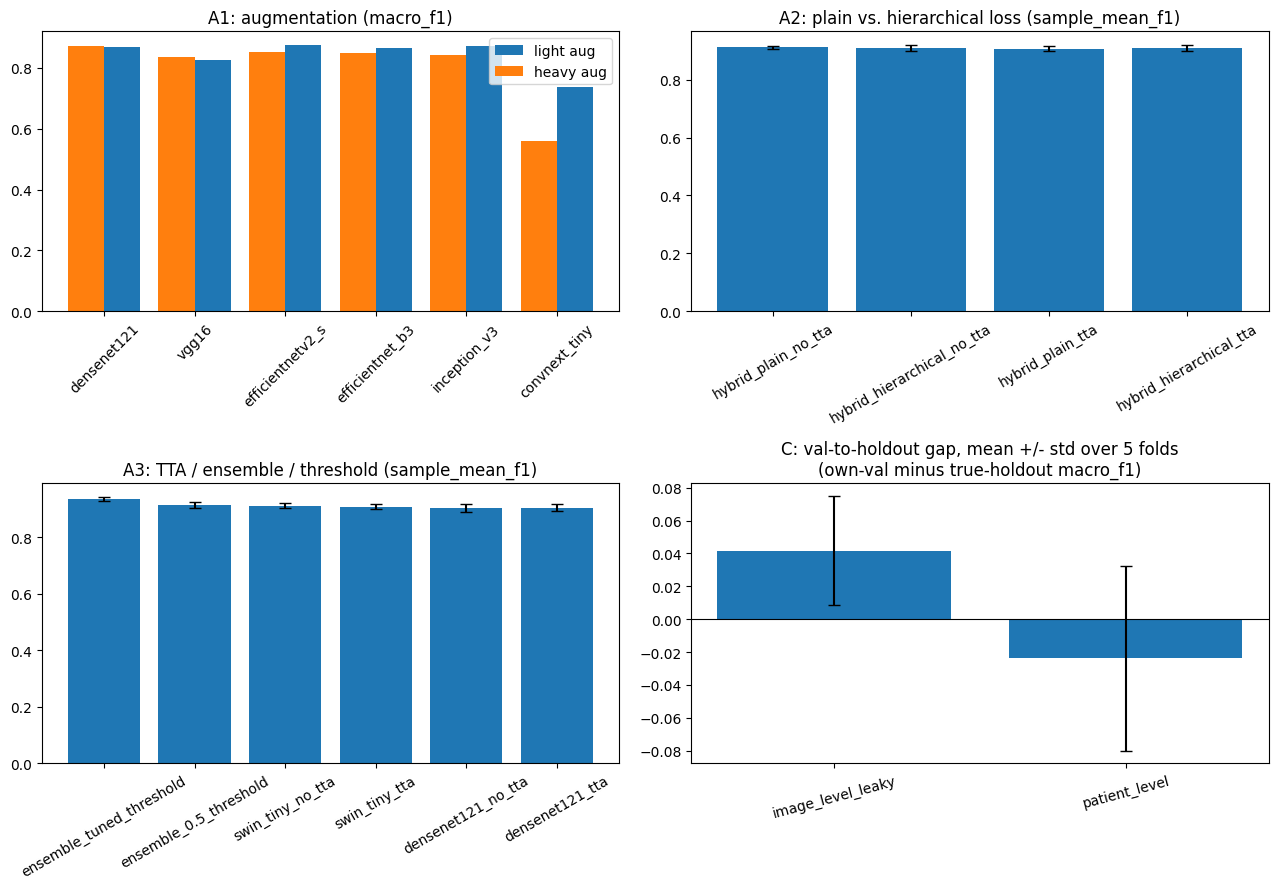


Section B (fusion ablation):
   fusion  sample_mean_f1  macro_f1
     gate        0.909701  0.836324
fixed_avg        0.897420  0.823199


In [38]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0, 0].bar(aug_ablation["backbone"], aug_ablation["light_aug_macro_f1"], width=0.4,
               label="light aug", align="edge")
axes[0, 0].bar(aug_ablation["backbone"], aug_ablation["heavy_aug_macro_f1"], width=-0.4,
               label="heavy aug", align="edge")
axes[0, 0].set_title("A1: augmentation (macro_f1)")
axes[0, 0].tick_params(axis="x", rotation=45)
axes[0, 0].legend()

axes[0, 1].bar(loss_ablation["setup"], loss_ablation["sample_mean_f1_mean"],
               yerr=loss_ablation["sample_mean_f1_std"], capsize=4)
axes[0, 1].set_title("A2: plain vs. hierarchical loss (sample_mean_f1)")
axes[0, 1].tick_params(axis="x", rotation=30)

axes[1, 0].bar(tta_ablation["setup"], tta_ablation["sample_mean_f1_mean"],
               yerr=tta_ablation["sample_mean_f1_std"], capsize=4)
axes[1, 0].set_title("A3: TTA / ensemble / threshold (sample_mean_f1)")
axes[1, 0].tick_params(axis="x", rotation=30)

gap_mean = leakage_summary[("val_to_holdout_gap", "mean")]
gap_std = leakage_summary[("val_to_holdout_gap", "std")]
axes[1, 1].bar(gap_mean.index, gap_mean.values, yerr=gap_std.values, capsize=4)
axes[1, 1].axhline(0, color="black", linewidth=0.8)
axes[1, 1].set_title("C: val-to-holdout gap, mean +/- std over 5 folds\n(own-val minus true-holdout macro_f1)")
axes[1, 1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig("/kaggle/working/runs/ablation_summary_chart.png", dpi=120)
plt.show()

print("\nSection B (fusion ablation):")
print(fusion_results[["fusion", "sample_mean_f1", "macro_f1"]].to_string(index=False))


## Before this session ends

**Click "Save Version"**, or at minimum download `runs/` in full
(`ablation_fusion_results.csv`, `ablation_leakage_results.csv`,
`ablation_summary_chart.png`, and every run's checkpoints), plus
`index.csv` and `splits/` -- `/kaggle/working` is wiped when the
session ends.
